# AP03 – Machine Learning 2

## Overview Klassifikationsmodelle

| Modell / Titel im Spick | Wann anwenden? | Vorteil | Einschränkung |
|---|---|---|---|
| Logistische Regression | Wenn du die **Wahrscheinlichkeit für ein Ja/Nein-Ergebnis** schätzen und den Einfluss eines Merkmals erklären willst. **Bsp.:** Anhand der Lernstunden schätzt das Modell die Wahrscheinlichkeit, eine Prüfung zu bestehen. Ein positiver Koeffizient für Lernstunden bedeutet: mehr Lernstunden → höhere geschätzte Bestehenswahrscheinlichkeit | Einfaches Basismodell, Richtung der Zusammenhänge anhand der Koeffizienten interpretierbar | Komplexe Zusammenhänge benötigen zusätzliche passende Terme, Skalierung häufig sinnvoll |
| Klassifikationsbäume / Classification Trees | Wenn die Klassenzuordnung durch **Wenn-dann-Regeln** nachvollziehbar sein soll. **Bsp.:** Ein Baum lernt aus Paketdaten: «Passt das Paket ins Fach und wiegt es höchstens 10 kg → Paketstation, sonst → Schalter». Du kannst den Weg für jedes Paket ablesen | Regeln gut nachvollziehbar, keine Skalierung nötig | Tiefe Bäume können overfitten und stark auf kleine Datenänderungen reagieren |
| Random Forest Classification | Wenn mehrere Merkmale zusammenspielen und du die Einschätzungen **vieler unterschiedlicher Bäume** kombinieren willst. **Bsp.:** Für dieselbe Lieferung schätzen drei Bäume anhand von Entfernung, Verkehr und Wetter die Wahrscheinlichkeit einer Verspätung auf 60 %, 70 % und 80 %. Der Wald mittelt auf 70 % | Kombiniert viele Bäume und reduziert deren Schwankungen, keine Skalierung nötig | Einzelne Vorhersagen schwerer nachvollziehbar als bei einem einzelnen Baum |
| Gradient Boosting Classification | Wenn kleine Bäume die **bisherigen Schätzungen schrittweise verbessern** sollen. **Bsp.:** Das erste Modell schätzt die Verspätungsgefahr bei kurzen Lieferwegen als tief ein. Bei kurzen Wegen im Feierabendverkehr ist die Schätzung häufig zu tief. Der nächste Baum lernt dafür eine Korrektur | Kann komplexe Zusammenhänge erfassen und hohe Vorhersagegüte erreichen, keine Skalierung nötig | Lernrate, Baumtiefe und Anzahl Bäume gemeinsam abstimmen, Overfitting möglich |
| k-Nearest Neighbours, k-NN | Wenn du einen neuen Fall anhand der **ähnlichsten bekannten Fälle** einordnen willst. **Bsp.:** Von den fünf Songs mit dem ähnlichsten Tempo und Bassanteil gehören vier zur Klasse «Dance». Bei gleich gewichteten Nachbarn erhält der neue Song die Klasse «Dance» | Anschauliches Prinzip, Klasse anhand der nächsten Nachbarn bestimmen | Skalierung wichtig, empfindlich gegenüber unwichtigen Merkmalen und der Wahl von k |
| Stützvektormaschine (SVM) | Wenn du zwei Klassen durch eine **Grenze mit möglichst grossem Sicherheitsabstand** trennen willst. **Bsp.:** Schrauben vom Typ A sind meist kurz und dünn, solche vom Typ B lang und dick. Im Diagramm aus Länge und Dicke legt die SVM eine Trennlinie zwischen die Gruppen. Die Seite der Linie bestimmt den Typ einer neuen Schraube | Mit einem Kernel auch gekrümmte Klassengrenzen möglich | Skalierung wichtig, C und Kernel sorgfältig wählen, Wahrscheinlichkeiten nicht automatisch verfügbar |

## Logistische Regression

### Logistische Regression
- Aus Eingaben Klassenwahrscheinlichkeiten berechnen
- **Definition:** Ein Verfahren des überwachten Lernens, das trotz seines Namens zur Klassifikation gehört, bei zwei Klassen schätzt es die Wahrscheinlichkeit für Klasse 1
- **Zweck und Anwendung:** Verwenden, wenn eine Beobachtung einer von zwei Klassen zugeordnet werden soll, bspw. tödlicher oder nicht tödlicher Lawinenunfall
- **Input und Voraussetzungen:** Beim Training numerische Eingaben und bekannte Klassenzuordnungen, bspw. `0` und `1`, für die folgende Einzelberechnung genügt ein vorgegebener Score
- **Linearer Score:** Eingaben werden mit Koeffizienten gewichtet und zusammengezählt → `z = β₀ + β₁ × x`, bei mehreren Eingaben kommen weitere gewichtete Beiträge hinzu
- **Sigmoid-Funktion:** Wandelt den Score in eine Wahrscheinlichkeit um → `p = 1 / (1 + exp(−z))`, die Wahrscheinlichkeit liegt zwischen 0 und 1
- **Koeffizienten:** Ein positiver Koeffizient bedeutet, dass grössere Werte dieser Eingabe die geschätzte Wahrscheinlichkeit für Klasse 1 erhöhen, bei gleichbleibenden anderen Eingaben, die Änderung ist nicht konstant in Prozentpunkten
- **Training:** Die Koeffizienten werden anhand der Trainingsdaten geschätzt, Grundlage ist Log-Loss bzw. Maximum Likelihood, später übernimmt `.fit()` die Berechnung
- **Schwellenwert:** Für eine konkrete Klasse die Wahrscheinlichkeit mit einem Grenzwert vergleichen → bei `p >= threshold` Klasse 1, sonst Klasse 0
- **Bsp. aus der Aufgabe:** Score `z = 1` → `p ≈ 0.731`, beim Schwellenwert `0.5` folgt Klasse 1
- **Interpretation:** Das Modell schätzt für diese Beobachtung ungefähr 73.1 % Wahrscheinlichkeit für Klasse 1, das ist keine Sicherheit und keine Trefferquote des gesamten Modells
- **Stolperstein:** Score, Wahrscheinlichkeit und Klasse sind unterschiedliche Ergebnisse, der Score 1 bedeutet nicht 100 % Wahrscheinlichkeit

In [1]:
#Verwenden, wenn ein gegebener Score in eine Wahrscheinlichkeit und anschliessend in eine Klasse umgerechnet werden soll
import numpy as np                                                              #Import-Setup für Datei 2, numerische Berechnungen


#1. Vorgegebenen Score und Schwellenwert eintragen
logistic_demo_score = 1                                                         #Score aus der Aufgabe, noch keine Wahrscheinlichkeit
logistic_demo_threshold = 0.5                                                   #Ab dieser Wahrscheinlichkeit Klasse 1 vorhersagen
#ANPASSEN: Score und Schwellenwert durch die Werte aus der Aufgabe ersetzen


#2. Score mit der Sigmoid-Funktion umrechnen
logistic_demo_probability = 1 / (
    1 + np.exp(-logistic_demo_score)
)                                                                               #Wahrscheinlichkeit für Klasse 1 berechnen
#HINWEIS: Diese Formel bleibt gleich, wenn du nur den Score ersetzt


#3. Wahrscheinlichkeit in eine Klasse umwandeln
logistic_demo_class = int(
    logistic_demo_probability >= logistic_demo_threshold
)                                                                               #Vergleich ergibt True oder False, int() macht daraus 1 oder 0
#HINWEIS: Diese Regel verwendet die Codierung 0 und 1, ihre fachliche Bedeutung hängt von der Aufgabe ab


#4. Ergebnisse anzeigen
print(f'Score: {logistic_demo_score}')
print(f'Wahrscheinlichkeit für Klasse 1: {logistic_demo_probability:.3f}')
print(f'Das entspricht {logistic_demo_probability:.1%}')
print(f'Vorhergesagte Klasse bei Schwellenwert {logistic_demo_threshold}: {logistic_demo_class}')
#ANPASSEN: Bei Bedarf Klasse 1 in der Ausgabe konkret benennen, bspw. «Service nötig» oder «tödlicher Unfall»

Score: 1
Wahrscheinlichkeit für Klasse 1: 0.731
Das entspricht 73.1%
Vorhergesagte Klasse bei Schwellenwert 0.5: 1


### Lawinendaten vorbereiten
- Klassenanteile beim Train/Test-Split erhalten
- **Zweck und Anwendung:** Daten für eine binäre Klassifikation vorbereiten, hier soll anhand der Anzahl vollständig verschütteter Personen ein tödlicher Unfall vorhergesagt werden
- **Input:** `avalanche_accidents_switzerland.csv`, jede Zeile beschreibt einen erfassten Lawinenunfall
- **Auswahl gemäss Aufgabe:** Nur hydrologische Jahre ab `2000/01` verwenden und Zeilen ohne die benötigten Modellangaben entfernen
- **Feature `fully_buried`:** Anzahl vollständig verschütteter Personen, als zweidimensionaler DataFrame an das Modell übergeben
- **Zielvariable `fatal`:** `1 = Unfall mit mindestens einer verstorbenen Person`, `0 = Unfall ohne verstorbene Person`, die Klassifikation betrifft den Unfall und nicht das Überleben einer einzelnen Person
- **`stratify=y`:** Teilt die Daten so auf, dass die Klassenanteile in Training und Test ungefähr den Anteilen der Ausgangsdaten entsprechen
- **`test_size=0.2`:** Reserviert 20 % für die abschliessende Testbewertung, die restlichen 80 % dienen dem Training
- **Output und Kontrolle:** Zeilenzahlen und Klassenanteile vergleichen, ähnliche Anteile bestätigen die gewünschte geschichtete Aufteilung, es wird noch kein Modell trainiert
- **Interpretationsgrenze:** Das Modell untersucht tödliche Ausgänge unter bereits erfassten Unfällen, es sagt nicht vorher, ob auf einer Tour eine Lawine auftreten wird
- **Verfügbarkeit der Eingabe:** Die Anzahl vollständig Verschütteter ist erst nach dem Unfall bekannt, dieses Feature eignet sich deshalb nicht für eine Vorhersage vor Tourbeginn
- **Stolpersteine:** Die positive Klasse muss fachlich klar definiert sein, Klassenanteile allein sagen noch nichts über die Modellqualität aus

In [2]:
#Verwenden, um Daten für eine binäre Klassifikation vorzubereiten und die Klassenanteile beim Split ungefähr zu erhalten
import pandas as pd
from sklearn.model_selection import train_test_split
#Import-Setup für Datei 2, NumPy wurde bereits als np importiert


#1. Daten einmal laden
df_ap03spick_avalanches = pd.read_csv(
    'avalanche_accidents_switzerland.csv'
)                                                                               #CSV-Datei aus dem Arbeitsverzeichnis laden
#ANPASSEN: Dateiname und ggf. Pfad ersetzen
#ACHTUNG: Ist der DataFrame bereits vorhanden, Ladezeile weglassen und seinen Namen unten verwenden


#2. Auf den Zeitraum aus der Aufgabe einschränken
df_ap03spick_avalanches_model = df_ap03spick_avalanches.loc[
    df_ap03spick_avalanches['hydrological_year'] >= '2000/01'
].copy()                                                                        #Nur Unfälle ab dem hydrologischen Jahr 2000/01 übernehmen
#ANPASSEN: DataFrame, Filterspalte und Grenze gemäss Aufgabe ersetzen
#HINWEIS: Dieser Textvergleich funktioniert hier wegen des einheitlichen Formats YYYY/YY
#HINWEIS: Ohne verlangten Zeitraumfilter stattdessen df_ap03spick_avalanches.copy() verwenden


#3. Eingaben und Ziel festlegen
avalanche_features = ['fully_buried']                                           #Damit soll das Modell vorhersagen
avalanche_target = 'fatal'                                                      #Das soll das Modell vorhersagen
#ANPASSEN: Eingabespalten und Zielspalte gemäss Aufgabe einsetzen
#ACHTUNG: Zielspalte nicht zusätzlich als Eingabespalte aufnehmen

df_ap03spick_avalanches_model = (
    df_ap03spick_avalanches_model
    .dropna(subset=avalanche_features + [avalanche_target])
    .copy()
)                                                                               #Zeilen ohne benötigte Modellangaben entfernen
#ANPASSEN: Diese Bereinigung nur übernehmen, wenn sie zur Aufgabe passt

X_avalanches = df_ap03spick_avalanches_model[avalanche_features]                #Eingaben als Tabelle, auch bei nur einer Spalte
y_avalanches = df_ap03spick_avalanches_model[avalanche_target]                  #Tatsächliche Klassen als Series


#4. Training und Test mit ähnlichen Klassenanteilen erstellen
X_train_avalanches, X_test_avalanches, y_train_avalanches, y_test_avalanches = train_test_split(
    X_avalanches, y_avalanches,                                                 #Eingaben und richtige Antworten gemeinsam aufteilen
    test_size=0.2,                                                              #20 % Testdaten, 80 % Trainingsdaten
    stratify=y_avalanches,                                                      #Klassenanteile in beiden Teilen ungefähr erhalten
    random_state=42                                                             #Dieselbe zufällige Aufteilung bei jeder Ausführung
)
#ANPASSEN: Eingabe- und Zielvariablen ersetzen, bei stratify dieselbe Zielvariable wie oben einsetzen
#ANPASSEN: test_size und random_state gemäss Aufgabe setzen
#ACHTUNG: Sind Trainings- und Testdaten bereits vorbereitet, Schritte 1–4 überspringen und diese direkt verwenden


#5. Daten und Klassenanteile kontrollieren
display(df_ap03spick_avalanches_model[
    avalanche_features + [avalanche_target]
].head())                                                                       #Eingaben und tatsächliche Klasse nebeneinander anzeigen

print('Verwendete Unfälle:', len(y_avalanches))
print('Trainingsdaten:', len(y_train_avalanches))
print('Testdaten:', len(y_test_avalanches))

avalanche_class_shares = pd.DataFrame({
    'Gesamt (%)': y_avalanches.value_counts(normalize=True) * 100,
    'Training (%)': y_train_avalanches.value_counts(normalize=True) * 100,
    'Test (%)': y_test_avalanches.value_counts(normalize=True) * 100
}).sort_index()

display(avalanche_class_shares.round(1))                                        #Anteile von Klasse 0 und Klasse 1 vergleichen
#ANPASSEN: Falls du die Zielvariablen umbenennst, ihre Namen auch in Schritt 5 ersetzen

,fully_buried,fatal
1312,1.0,1
1313,1.0,0
1314,1.0,1
1315,2.0,0
1316,0.0,0


Verwendete Unfälle: 2876
Trainingsdaten: 2300
Testdaten: 576


,Gesamt (%),Training (%),Test (%)
fatal,,,
0,86.8,86.8,86.8
1,13.2,13.2,13.2


### Logistische Regression trainieren
- Klassenanteile beim Train/Test-Split erhalten
- **Zweck und Anwendung:** Eine binäre Zielvariable anhand von Eingabemerkmalen vorhersagen, hier die Wahrscheinlichkeit eines tödlichen Ausgangs unter erfassten Lawinenunfällen
- **Input und Voraussetzungen:** Vorbereitete numerische Trainingsmerkmale und bekannte Klassen, hier `X_train_avalanches` mit `fully_buried` und `y_train_avalanches` mit `fatal`
- **`LogisticRegression()`:** Erstellt das Modell, scikit-learn verwendet standardmässig Regularisierung, welche die Koeffizienten begrenzt
- **`.fit(X_train, y_train)`:** Lernt Achsenabschnitt und Koeffizienten ausschliesslich anhand der Trainingsdaten
- **`.intercept_`:** Achsenabschnitt des linearen Scores, bei nur einer Eingabe der Score für `x = 0`, keine Wahrscheinlichkeit
- **`.coef_`:** Koeffizienten des linearen Scores, ein positiver Wert bedeutet höhere Wahrscheinlichkeit für Klasse 1 bei grösseren Eingabewerten und gleichbleibenden anderen Merkmalen
- **Interpretation:** Ein positiver Koeffizient von `fully_buried` bedeutet, dass mehr vollständig verschüttete Personen im Modell mit einer höheren Wahrscheinlichkeit für einen tödlichen Unfall verbunden sind
- **Stolperstein:** Der Koeffizient ist keine Änderung in Prozentpunkten, die Wahrscheinlichkeit ergibt sich erst durch die Sigmoid-Funktion
- **`.predict_proba(X_test)`:** Liefert für jede Testbeobachtung eine Wahrscheinlichkeit pro Klasse
- **`.classes_`:** Zeigt die Klassenreihenfolge der Wahrscheinlichkeitsspalten, bei Klassen `[0, 1]` gehört Spalte 0 zu Klasse 0 und Spalte 1 zu Klasse 1
- **`[:, 1]`:** Wählt bei dieser Klassenreihenfolge für alle Beobachtungen die Wahrscheinlichkeit von Klasse 1 aus
- **Output und Interpretation:** Bspw. eine geschätzte Wahrscheinlichkeit von 0.7 bedeutet 70 % für einen tödlichen Unfall gemäss Modell, nicht dass 70 % der Personen sterben oder das Modell 70 % Accuracy erreicht
- **Grafik:** Zeigt bei diesem Modell mit genau einer Eingabe die geschätzte Wahrscheinlichkeit über der Anzahl vollständig Verschütteter, sie ist keine Bewertung der Vorhersagequalität
- **Weitere Bewertung:** Die Testwahrscheinlichkeiten verwenden wir anschliessend für Confusion Matrix, Schwellenwerte und ROC/AUC

Klassenreihenfolge: [0 1]
Achsenabschnitt des Scores: -3.096


,Merkmal,Koeffizient
0,fully_buried,2.257


,fully_buried,actual_fatal,probability_fatal
3926,1.0,0,0.302
3457,0.0,0,0.043
2501,0.0,0,0.043
4122,0.0,0,0.043
3675,0.0,0,0.043
1645,0.0,0,0.043
1498,1.0,0,0.302
1649,0.0,0,0.043
3038,0.0,0,0.043
3483,0.0,0,0.043


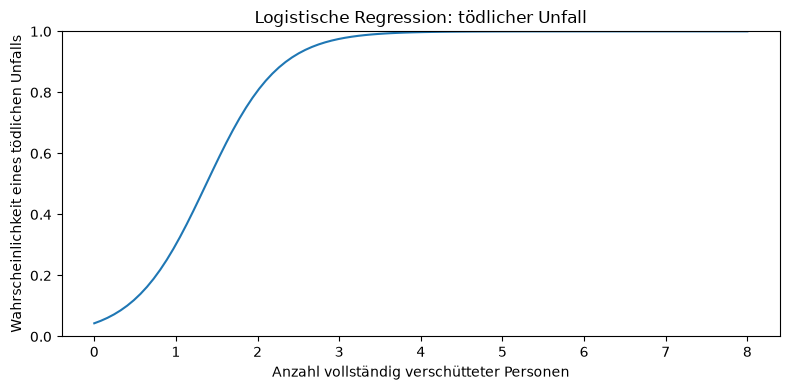

In [3]:
#Verwenden, um eine logistische Regression zu trainieren und Wahrscheinlichkeiten für Klasse 1 zu berechnen
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
#VORAUSSETZUNG: pd und np sind importiert, die Trainings- und Testdaten der Lawinen sind vorbereitet

#1. Modell erstellen und trainieren
logistic_avalanches = LogisticRegression()
logistic_avalanches.fit(X_train_avalanches, y_train_avalanches)
#ANPASSEN: Modellparameter nur gemäss Aufgabe ergänzen
#ANPASSEN: X_train_avalanches und y_train_avalanches durch deine Trainingsvariablen ersetzen


#2. Gelernte Koeffizienten anzeigen
print('Klassenreihenfolge:', logistic_avalanches.classes_)
print(f'Achsenabschnitt des Scores: {logistic_avalanches.intercept_[0]:.3f}')

display(pd.DataFrame({
    'Merkmal': X_train_avalanches.columns,
    'Koeffizient': logistic_avalanches.coef_[0]
}).round(3))
#ANPASSEN: X_train_avalanches wie in Schritt 1 ersetzen
#HINWEIS: Diese Koeffizientenausgabe gilt für eine binäre Klassifikation


#3. Wahrscheinlichkeiten für die Testbeobachtungen berechnen
probability_avalanches = logistic_avalanches.predict_proba(
    X_test_avalanches
)[:, 1]                                                                         #Bei Klassenreihenfolge [0, 1] die Wahrscheinlichkeit für Klasse 1 auswählen
#ANPASSEN: X_test_avalanches durch deine Testmerkmale ersetzen
#ACHTUNG: Spalte 1 gehört zur zweiten Klasse in classes_, deren fachliche Bedeutung prüfen

probability_check_avalanches = X_test_avalanches.copy()
probability_check_avalanches['actual_fatal'] = y_test_avalanches
probability_check_avalanches['probability_fatal'] = probability_avalanches

display(probability_check_avalanches.head(10).round(3))                         #Testeingaben, tatsächliche Klasse und Wahrscheinlichkeit nebeneinander prüfen
#ANPASSEN: y_test_avalanches durch deine Testzielwerte ersetzen
#ANPASSEN: actual_fatal und probability_fatal passend zu deiner Zielklasse benennen


#4. Optional: Wahrscheinlichkeitskurve bei genau einer Eingabespalte zeichnen
logistic_curve_avalanches = pd.DataFrame({
    'fully_buried': np.linspace(0, 8, 100)                                      #100 Werte zwischen 0 und 8 vollständig Verschütteten
})
curve_probability_avalanches = logistic_avalanches.predict_proba(
    logistic_curve_avalanches
)[:, 1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    logistic_curve_avalanches['fully_buried'],
    curve_probability_avalanches
)
ax.set_xlabel('Anzahl vollständig verschütteter Personen')
ax.set_ylabel('Wahrscheinlichkeit eines tödlichen Unfalls')
ax.set_title('Logistische Regression: tödlicher Unfall')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

#ANPASSEN: fully_buried an beiden Stellen, Bereich 0 bis 8 sowie Beschriftungen an deine Aufgabe anpassen
#ACHTUNG: Bei mehreren Eingabespalten Schritt 4 weglassen, diese Kurve gilt nur für das Modell mit einer Eingabe

## Klassifikation bewerten

### Overview Klassifikationskennzahlen

| Kennzahl | Wann anwenden? | Anschauliches Beispiel | Benötigte Vorhersage |
|---|---|---|---|
| Accuracy | Wenn du wissen willst, welcher Anteil insgesamt richtig klassifiziert wurde, besonders bei ähnlich häufigen Klassen und vergleichbaren Fehlerkosten | Von 100 Fällen sind 90 richtig vorhergesagt → Accuracy = 90 % | Vorhergesagte Klassen |
| Precision | Wenn positive Vorhersagen möglichst zuverlässig sein sollen, also wenige Fehlalarme entstehen sollen | Von 10 als Spam markierten E-Mails sind 9 tatsächlich Spam → Precision = 90 % | Vorhergesagte Klassen |
| Recall | Wenn möglichst viele tatsächlich positive Fälle erkannt werden sollen, also wenige übersehen werden sollen | Von 10 tatsächlichen Spam-E-Mails werden 8 erkannt → Recall = 80 % | Vorhergesagte Klassen |
| F1 | Wenn sowohl Fehlalarme als auch übersehene positive Fälle wichtig sind, besonders bei ungleichen Klassenanteilen | Ein Spamfilter soll möglichst viel Spam erkennen und gleichzeitig wenige normale E-Mails als Spam markieren | Vorhergesagte Klassen |
| ROC-AUC | Wenn du beurteilen willst, wie gut das Modell positive Fälle vor negativen einordnet, unabhängig von einem einzelnen Schwellenwert | Eine AUC von 0.9 bedeutet, dass ein zufällig gewählter positiver Fall mit etwa 90 % Wahrscheinlichkeit einen höheren Score erhält als ein zufällig gewählter negativer Fall | Wahrscheinlichkeiten für die positive Klasse oder Entscheidungsscores |

- Die positive Klasse zuerst festlegen, bspw. 1 = Spam und 0 = normale E-Mail
Accuracy kann bei ungleichen Klassen täuschen, bei 95 % normalen E-Mails erreicht ein Modell bereits 95 % Accuracy, wenn es jede E-Mail als normal einstuft
Precision, Recall und F1 hängen vom gewählten Schwellenwert ab. ROC-AUC bewertet die Rangtrennung über verschiedene Schwellenwerte hinweg

### Confusion Matrix & Kennzahlen
- Richtige und falsche Klassifikationen beurteilen
- **Definition:** Die Confusion Matrix zählt, welche tatsächlichen Klassen richtig bzw. falsch vorhergesagt werden
- **Zweck und Anwendung:** Ein Klassifikationsmodell bewerten und erkennen, welche Fehler es macht, besonders bei unterschiedlich häufigen Klassen
- **Input:** Tatsächliche und vorhergesagte Klassen derselben Beobachtungen in derselben Reihenfolge, bei Wahrscheinlichkeiten zuerst einen Schwellenwert anwenden
- **Positive Klasse:** Hier `1 = tödlicher Unfall`, positiv bedeutet die betrachtete Zielklasse und nicht «gut»
- **Anordnung bei `labels=[0, 1]`:** Zeilen = tatsächliche Klassen, Spalten = vorhergesagte Klassen → `[[TN, FP], [FN, TP]]`
- **TN (True Negative):** Tatsächlich Klasse 0, korrekt als 0 vorhergesagt
- **FP (False Positive):** Tatsächlich Klasse 0, fälschlich als 1 vorhergesagt → Fehlalarm
- **FN (False Negative):** Tatsächlich Klasse 1, fälschlich als 0 vorhergesagt → positiver Fall übersehen
- **TP (True Positive):** Tatsächlich Klasse 1, korrekt als 1 vorhergesagt
- **Accuracy:** `(TP + TN) / Gesamtzahl` → welcher Anteil aller Beobachtungen wurde richtig klassifiziert?
- **Precision:** `TP / (TP + FP)` → wie viele der als positiv vorhergesagten Fälle sind tatsächlich positiv?
- **Recall / True Positive Rate:** `TP / (TP + FN)` → wie viele der tatsächlich positiven Fälle wurden erkannt?
- **FPR (False Positive Rate):** `FP / (FP + TN)` → welcher Anteil der tatsächlich negativen Fälle wurde fälschlich als positiv eingestuft?
- **F1:** `2 × Precision × Recall / (Precision + Recall)` → harmonisches Mittel aus Precision und Recall, berücksichtigt TN nicht
- **Wertebereich:** Alle genannten Kennzahlen liegen bei definiertem Nenner zwischen 0 und 1, für Accuracy, Precision, Recall und F1 sind grössere Werte besser, für FPR kleinere
- **Bsp. aus der Aufgabe:** TN = 75, FP = 22, FN = 24, TP = 50 → Precision ≈ 0.694 und Recall ≈ 0.676
- **Interpretation:** Rund 69.4 % der vorhergesagten positiven Fälle sind tatsächlich positiv, rund 67.6 % aller tatsächlich positiven Fälle werden gefunden
- **Baseline:** Wer immer Klasse 0 vorhersagt, erreicht eine Accuracy entsprechend dem Anteil der Klasse 0, erkennt aber keinen positiven Fall
- **Stolpersteine:** Hohe Accuracy allein kann bei seltenen positiven Fällen täuschen, welche Kennzahl besonders wichtig ist, hängt von den Folgen der Fehler ab
- **Nicht definierte Kennzahlen:** Ohne vorhergesagte positive Fälle ist Precision nicht definiert, ohne tatsächliche positive Fälle ist Recall nicht definiert, `zero_division=0` gibt in solchen Fällen ersatzweise 0 aus

Accuracy:  0.731
Precision: 0.694
Recall:    0.676
FPR:       0.227
F1:        0.685


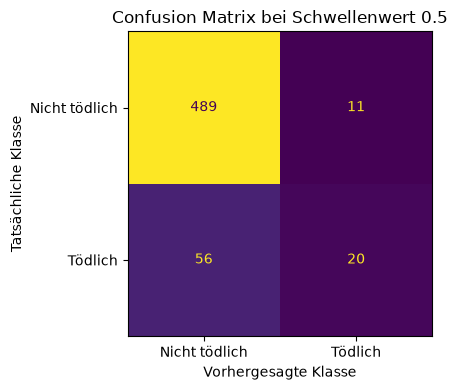

Accuracy:  0.884
Precision: 0.645
Recall:    0.263
F1:        0.374
FPR: 0.022
Accuracy bei immer Klasse 0: 0.868


In [4]:
#Variante 1: Verwenden, wenn TN, FP, FN und TP vorgegeben sind und Kennzahlen daraus berechnet werden sollen


#1. Fallzahlen aus der Aufgabe eintragen
metric_tn, metric_fp, metric_fn, metric_tp = 75, 22, 24, 50
#ANPASSEN: Die vier Zahlen in der Reihenfolge TN, FP, FN, TP ersetzen


#2. Kennzahlen berechnen
metric_accuracy = (metric_tp + metric_tn) / (
    metric_tn + metric_fp + metric_fn + metric_tp
)
metric_precision = metric_tp / (metric_tp + metric_fp)                          #Anteil richtiger positiver Vorhersagen
metric_recall = metric_tp / (metric_tp + metric_fn)                             #Anteil erkannter tatsächlicher positiver Fälle
metric_fpr = metric_fp / (metric_fp + metric_tn)                                #Fehlalarmanteil unter den tatsächlichen negativen Fällen
metric_f1 = 2 * metric_tp / (2 * metric_tp + metric_fp + metric_fn)
#HINWEIS: Formeln bleiben bei anderen Fallzahlen gleich
#ACHTUNG: Ein Nenner von 0 macht die jeweilige Berechnung undefiniert


#3. Ergebnisse anzeigen
print(f'Accuracy:  {metric_accuracy:.3f}')
print(f'Precision: {metric_precision:.3f}')
print(f'Recall:    {metric_recall:.3f}')
print(f'FPR:       {metric_fpr:.3f}')
print(f'F1:        {metric_f1:.3f}')



#Variante 2: Verwenden, wenn tatsächliche Testklassen und vorhergesagte Wahrscheinlichkeiten für Klasse 1 vorliegen
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score
)
#VORAUSSETZUNG: np, pd und plt sind importiert, Testzielwerte und Testwahrscheinlichkeiten sind vorbereitet
#HINWEIS: Variante 2 ist unabhängig von Variante 1

#1. Tatsächliche Klassen, Wahrscheinlichkeiten und Schwellenwert zuordnen
classification_actual = y_test_avalanches
classification_probability = probability_avalanches
classification_threshold = 0.5
classification_names = ['Nicht tödlich', 'Tödlich']                             #Beschriftungen für Klasse 0 und Klasse 1
#ANPASSEN: Testzielwerte, Wahrscheinlichkeiten für Klasse 1 und Schwellenwert gemäss Aufgabe ersetzen
#ANPASSEN: Beide Klassennamen in der Reihenfolge 0, 1 passend zur Aufgabe ersetzen

#2. Wahrscheinlichkeiten in Klassen umwandeln
classification_predicted = (
    classification_probability >= classification_threshold
).astype(int)                                                                   #Ab dem Schwellenwert Klasse 1, sonst Klasse 0
#ANPASSEN: Liegen bereits vorhergesagte Klassen vor, stattdessen classification_predicted = deine_testvorhersagen setzen

#3. Confusion Matrix berechnen und zeichnen
classification_cm = confusion_matrix(
    classification_actual, classification_predicted,
    labels=[0, 1]                                                               #Reihenfolge für [[TN, FP], [FN, TP]] festlegen
)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    classification_cm,
    display_labels=classification_names
).plot(ax=ax, colorbar=False)
ax.set_xlabel('Vorhergesagte Klasse')
ax.set_ylabel('Tatsächliche Klasse')
ax.set_title(f'Confusion Matrix bei Schwellenwert {classification_threshold}')
plt.tight_layout()
plt.show()
#ANPASSEN: Bei bereits gegebenen Klassenvorhersagen ohne Schwellenwert den Titel auf 'Confusion Matrix' ändern

#4. Kennzahlen und Vergleichsbasis anzeigen
classification_tn, classification_fp, classification_fn, classification_tp = (
    classification_cm.ravel()
)                                                                               #Vier Felder in der Reihenfolge TN, FP, FN, TP auslesen

print(f'Accuracy:  {accuracy_score(classification_actual, classification_predicted):.3f}')
print(f'Precision: {precision_score(classification_actual, classification_predicted, zero_division=0):.3f}')
print(f'Recall:    {recall_score(classification_actual, classification_predicted, zero_division=0):.3f}')
print(f'F1:        {f1_score(classification_actual, classification_predicted, zero_division=0):.3f}')

classification_negative_count = classification_tn + classification_fp
if classification_negative_count > 0:
    print(f'FPR: {classification_fp / classification_negative_count:.3f}')
else:
    print('FPR nicht definiert: Keine tatsächlichen Fälle der Klasse 0 vorhanden')

print(f'Accuracy bei immer Klasse 0: {np.mean(np.asarray(classification_actual) == 0):.3f}')
#HINWEIS: Schritt 3–4 bleibt bei Klassen 0 und 1 nach der Zuordnung in Schritt 1–2 unverändert
#ACHTUNG: Diese Variante setzt eine binäre Zielvariable mit den Klassen 0 und 1 voraus

### Klassifikationsschwellen & Fehlerkosten
- Fehlalarme und übersehene Fälle abwägen
- **Definition:** Der Schwellenwert legt fest, ab welcher vorhergesagten Wahrscheinlichkeit eine Beobachtung als Klasse 1 eingestuft wird → `p >= threshold`
- **Zweck und Anwendung:** Die Klasseneinteilung an die Folgen falscher Entscheidungen anpassen, bspw. wenn übersehene Servicefälle schwerer wiegen als unnötige Kontrollen
- **Input und Voraussetzungen:** Tatsächliche Klassen und vorhergesagte Wahrscheinlichkeiten für Klasse 1 derselben Beobachtungen, zusätzlich vorgegebene Schwellenwerte und ggf. Fehlerkosten
- **Schwellenwert senken:** Mehr Beobachtungen werden positiv eingestuft, Recall und FPR können nicht sinken, FN können nicht zunehmen und FP können nicht abnehmen
- **Schwellenwert erhöhen:** Weniger Beobachtungen werden positiv eingestuft, Recall und FPR können nicht steigen, FN können nicht abnehmen und FP können nicht zunehmen
- **Precision:** Steigt häufig bei höherem Schwellenwert, das ist aber nicht garantiert
- **Bsp.:** Bei Wahrscheinlichkeit 0.4 ergibt Schwellenwert 0.5 die Klasse 0, Schwellenwert 0.3 dagegen die Klasse 1
- **Fehlerkosten:** `Gesamtkosten = Kosten pro FN × FN + Kosten pro FP × FP`
- **Beispiel aus der Aufgabe:** Ein übersehener positiver Fall kostet beispielhaft 10 Einheiten, ein Fehlalarm 1 Einheit → `Gesamtkosten = 10 × FN + FP`
- **Interpretation:** Kleinere Gesamtkosten sind unter diesen Kostenannahmen besser, die Kosten sind hier illustrative Gewichte und keine tatsächlichen Geldbeträge
- **Was unverändert bleibt:** Modell und Wahrscheinlichkeiten werden nicht neu berechnet, nur die Grenze für die Klassenzuordnung verändert sich
- **Schwellenwert auswählen:** Anhand von Validierungsdaten bzw. geeigneter CV und fachlichen Fehlerkosten festlegen, anschliessend auf Testdaten bewerten
- **Vorgehen in dieser Aufgabe:** Zwei bereits festgelegte Schwellenwerte auf den Testdaten vergleichen, daraus keinen weiteren optimierten Schwellenwert auswählen
- **Stolperstein:** Ein höherer Recall allein bedeutet nicht insgesamt bessere Entscheidungen, zusätzliche Fehlalarme und deren Folgen mitberücksichtigen

In [5]:
#Verwenden, um vorgegebene Schwellenwerte anhand von Fehlalarmen, übersehenen Fällen und Fehlerkosten zu vergleichen
#VORAUSSETZUNG: np, pd und confusion_matrix sind importiert, Testzielwerte und Wahrscheinlichkeiten für Klasse 1 liegen vor

#1. Daten und zu vergleichende Schwellenwerte zuordnen
threshold_actual = y_test_avalanches                                            #Tatsächliche Klassen 0 und 1
threshold_probability = np.asarray(probability_avalanches)                      #Zugehörige Wahrscheinlichkeiten für Klasse 1
threshold_values = [0.5, 0.3]                                                   #Diese beiden festen Grenzen vergleichen
#ANPASSEN: Testzielwerte und Wahrscheinlichkeiten durch deine Variablen ersetzen, gleiche Reihenfolge sicherstellen
#ANPASSEN: threshold_values durch die vorgegebenen Schwellenwerte ersetzen


#2. Kosten je Fehler festlegen
threshold_cost_fn = 10                                                          #Kosten für einen übersehenen positiven Fall
threshold_cost_fp = 1                                                           #Kosten für einen Fehlalarm
#ANPASSEN: 10 und 1 durch die Fehlerkosten der Aufgabe ersetzen
#HINWEIS: Ohne vorgegebene Kosten die Kostenberechnung und Kostenspalte in Schritt 3 weglassen


#3. Für jeden Schwellenwert Klassen, Fehlerzahlen und Kosten berechnen
threshold_rows = []

for threshold_value in threshold_values:
    threshold_predicted = (
        threshold_probability >= threshold_value
    ).astype(int)                                                               #Ab der aktuellen Grenze Klasse 1 vorhersagen

    threshold_tn, threshold_fp, threshold_fn, threshold_tp = confusion_matrix(
        threshold_actual, threshold_predicted,
        labels=[0, 1]
    ).ravel()                                                                   #Fehler und richtige Vorhersagen abzählen

    threshold_positive_count = threshold_tp + threshold_fn
    threshold_recall = (
        threshold_tp / threshold_positive_count
        if threshold_positive_count > 0 else np.nan
    )                                                                           #Anteil erkannter positiver Fälle, ohne positive Fälle nicht definiert

    threshold_total_cost = (
        threshold_cost_fn * threshold_fn
        + threshold_cost_fp * threshold_fp
    )                                                                           #Anzahl jedes Fehlertyps mit seinen Kosten multiplizieren

    threshold_rows.append({
        'Schwellenwert': threshold_value,
        'FP: Fehlalarme': threshold_fp,
        'FN: übersehen': threshold_fn,
        'Recall': threshold_recall,
        'Gesamtkosten': threshold_total_cost
    })
#HINWEIS: Bei Klassen 0 und 1 bleiben die Berechnungen nach Anpassung von Schritt 1–2 unverändert


#4. Ergebnisse nebeneinander vergleichen
display(pd.DataFrame(threshold_rows).round(3))
#ACHTUNG: Diese Testauswertung vergleicht feste Vorgaben, keinen neuen Schwellenwert auf den Testdaten optimieren

,Schwellenwert,FP: Fehlalarme,FN: übersehen,Recall,Gesamtkosten
0,0.5,11,56,0.263,571
1,0.3,88,13,0.829,218


## ROC-Kurve & AUC
- Wie gut trennt das Modell die Klassen?
- **Definition:** Die ROC-Kurve zeigt das Verhältnis zwischen erkannten positiven Fällen und Fehlalarmen bei verschiedenen Schwellenwerten, die AUC fasst diese Kurve als Fläche zusammen
- **Zweck und Anwendung:** Beurteilen, ob das Modell tatsächlichen positiven Fällen tendenziell höhere Wahrscheinlichkeiten oder Scores zuordnet als negativen Fällen
- **Input und Voraussetzungen:** Tatsächliche Testklassen und zugehörige Wahrscheinlichkeiten für die positive Klasse, beide tatsächlichen Klassen müssen vorhanden sein, für diese Auswertung gilt `1 = positiv`
- **X-Achse – FPR:** `FP / (FP + TN)` → Anteil der tatsächlichen negativen Fälle, die fälschlich positiv vorhergesagt werden
- **Y-Achse – TPR / Recall:** `TP / (TP + FN)` → Anteil der tatsächlichen positiven Fälle, die erkannt werden
- **Schwellenwerte:** Jeder mögliche Schwellenwert erzeugt einen Punkt, beim Senken der Grenze werden mehr Fälle positiv eingestuft
- **Interpretation der Kurve:** Näher an der linken oberen Ecke ist günstiger → viele positive Fälle erkennen und wenige Fehlalarme erzeugen
- **Diagonale:** Vergleichslinie einer zufälligen Rangfolge im Erwartungswert, sie entspricht AUC 0.5
- **AUC (Area Under the ROC Curve):** Liegt zwischen 0 und 1, grösser bedeutet bessere Rangtrennung, 1 = perfekte Rangtrennung und 0.5 = keine bessere Rangtrennung als Zufall
- **Interpretation von AUC 0.90:** Bei einem zufällig ausgewählten positiven und negativen Fall erhält der positive Fall in 90 % der Paarvergleiche den höheren Score, Gleichstände werden zur Hälfte gezählt
- **AUC unter 0.5:** Die Rangfolge ist schlechter als die Zufallsreferenz, u.a. prüfen, ob die Wahrscheinlichkeit der richtigen Klasse verwendet wurde
- **Stolperstein:** AUC 0.90 bedeutet nicht 90 % richtig klassifizierte Beobachtungen, Accuracy und AUC beantworten unterschiedliche Fragen
- **Bezug zum Schwellenwert:** Eine andere feste Entscheidungsgrenze verändert die Confusion Matrix, bei unveränderten Wahrscheinlichkeiten bleibt die AUC gleich
- **Grenze der Aussage:** AUC bewertet die Rangfolge, nicht die Verlässlichkeit der Wahrscheinlichkeitswerte und nicht die Fehlerkosten eines konkreten Schwellenwerts

Test-AUC: 0.841


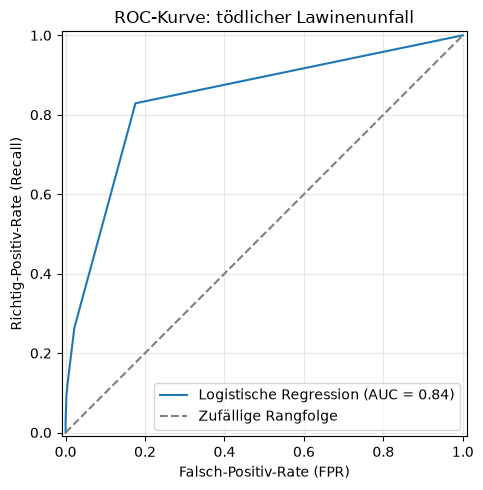

In [6]:
#Verwenden, um die Rangtrennung eines binären Klassifikationsmodells mit ROC-Kurve und AUC auf Testdaten zu bewerten
from sklearn.metrics import RocCurveDisplay, roc_auc_score
#VORAUSSETZUNG: plt ist importiert, tatsächliche Testklassen und Wahrscheinlichkeiten für Klasse 1 liegen vor


#1. Tatsächliche Klassen und Wahrscheinlichkeiten zuordnen
roc_actual = y_test_avalanches                                                  #Tatsächliche Klassen der Testunfälle
roc_probability = probability_avalanches                                        #Zugehörige Wahrscheinlichkeiten für Klasse 1
#ANPASSEN: Beide Variablen durch deine Testzielwerte und Wahrscheinlichkeiten für Klasse 1 ersetzen
#ACHTUNG: Gleiche Beobachtungen und Reihenfolge verwenden, beide tatsächlichen Klassen müssen enthalten sein
#ACHTUNG: Hier Wahrscheinlichkeiten oder passende kontinuierliche Scores verwenden, nicht die vorhergesagten Klassen 0/1


#2. AUC berechnen
roc_auc = roc_auc_score(roc_actual, roc_probability)                            #Rangtrennung über die möglichen Schwellenwerte bewerten
print(f'Test-AUC: {roc_auc:.3f}')
#HINWEIS: Diese Berechnung bleibt nach Anpassung von Schritt 1 unverändert

#3. ROC-Kurve und Zufallsreferenz zeichnen
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    roc_actual,
    roc_probability,
    name='Logistische Regression',                                              #Modellname für die Legende
    ax=ax
)
#ANPASSEN: name durch die Bezeichnung deines untersuchten Modells ersetzen

ax.plot(
    [0, 1], [0, 1],
    linestyle='--', color='grey', label='Zufällige Rangfolge'
)                                                                               #Diagonale mit AUC 0.5 als Vergleich einzeichnen

ax.set_xlabel('Falsch-Positiv-Rate (FPR)')
ax.set_ylabel('Richtig-Positiv-Rate (Recall)')
ax.set_title('ROC-Kurve: tödlicher Lawinenunfall')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
#ANPASSEN: Titel an deine Klassifikationsaufgabe anpassen, Achsenbeschriftungen bleiben gleich

## Klassifikationsbäume

### Gini-Unreinheit
- Wie gut trennt ein Split die Klassen?
- **Definition:** Gini misst, wie stark die Klassen in einem Knoten gemischt sind, ein reiner Knoten enthält nur eine Klasse
- **Zweck und Anwendung:** Mögliche Aufteilungen eines Klassifikationsbaums vergleichen, bevorzugt wird der Split mit der grössten Abnahme der Unreinheit
- **Input:** Anzahl Beobachtungen pro Klasse im Ausgangsknoten sowie im linken und rechten Kind, die Kinder müssen zusammen dieselben Beobachtungen wie der Ausgangsknoten enthalten
- **Gini bei zwei Klassen:** `G = 1 − p² − (1 − p)²`, dabei ist p der Anteil einer Klasse im Knoten
- **Wertebereich bei zwei Klassen:** 0 = rein, 0.5 = maximal gemischt mit 50 % je Klasse, bei mehr als zwei Klassen kann Gini grösser als 0.5 werden
- **Gewichteter Gini nach dem Split:** `(Anteil links × Gini links) + (Anteil rechts × Gini rechts)`, grössere Kinder zählen stärker
- **Gini-Abnahme:** `Gini vorher − gewichteter Gini nachher`, grösser bedeutet bessere Klassentrennung auf den Trainingsdaten
- **Unterschied zur Regression:** Regressionsbäume bewerten Aufteilungen anhand numerischer Zielwerte und quadratischer Fehler, Klassifikationsbäume hier anhand der Klassenanteile
- **Bsp. aus der Aufgabe:** 40 Überlebende und 60 Nichtüberlebende → `Gini = 1 − 0.4² − 0.6² = 0.48`, der Knoten ist nicht rein
- **Split «männlich?» laut Aufgabenbeispiel:** Gewichteter Gini = 0.36 → Abnahme = 0.12
- **Split «erste Klasse?»:** Gewichteter Gini ≈ 0.453 → Abnahme ≈ 0.027, der erste Split trennt die Klassen in diesem Beispiel besser
- **Interpretationsgrenze:** Die grössere Gini-Abnahme begründet die lokale Aufteilung, sie beweist keine gute Testleistung und keinen kausalen Einfluss des Merkmals
- **Alternative:** Entropie ist ein anderes Unreinheitsmass, die Aufgabe verwendet hier Gini

In [7]:
#Verwenden, wenn Klassenanzahlen vorgegeben sind und mögliche Splits anhand ihrer Gini-Abnahme verglichen werden sollen
#VORAUSSETZUNG: pd ist importiert, die folgenden Berechnungen gelten für zwei Klassen

#1. Klassenanzahlen im Ausgangsknoten eintragen
gini_parent_positive = 40                                                       #Klasse 1, hier überlebt
gini_parent_negative = 60                                                       #Klasse 0, hier nicht überlebt
#ANPASSEN: Beide Anzahlen durch die Werte des Ausgangsknotens ersetzen

gini_parent_total = gini_parent_positive + gini_parent_negative
gini_parent_p = gini_parent_positive / gini_parent_total
gini_parent = 1 - gini_parent_p ** 2 - (1 - gini_parent_p) ** 2

#2. Klassenanzahlen für die zu vergleichenden Splits eintragen
gini_splits = {
    'Männlich?': {
        'left': [12, 48],                                                       #Links: 12 positive und 48 negative Fälle
        'right': [28, 12]                                                       #Rechts: 28 positive und 12 negative Fälle
    },
    'Erste Klasse?': {
        'left': [15, 10],
        'right': [25, 50]
    }
}
#ANPASSEN: Splitnamen und Anzahlen ersetzen, jede Liste hat die Reihenfolge [positiv, negativ]
#ACHTUNG: Pro Split müssen beide Kinder zusammen die Klassenanzahlen aus Schritt 1 ergeben

#3. Gini der Kinder und Abnahme für jeden Split berechnen
gini_rows = []

for split_name, split_children in gini_splits.items():
    left_positive, left_negative = split_children['left']
    right_positive, right_negative = split_children['right']

    left_total = left_positive + left_negative
    right_total = right_positive + right_negative

    left_p = left_positive / left_total                                         #Positiven Anteil links berechnen
    right_p = right_positive / right_total                                      #Positiven Anteil rechts berechnen

    left_gini = 1 - left_p ** 2 - (1 - left_p) ** 2
    right_gini = 1 - right_p ** 2 - (1 - right_p) ** 2

    weighted_gini = (
        left_total / gini_parent_total * left_gini
        + right_total / gini_parent_total * right_gini
    )                                                                           #Gini der Kinder nach ihrer Grösse gewichten

    gini_rows.append({
        'Split': split_name,
        'Gini links': left_gini,
        'Gini rechts': right_gini,
        'Gewichteter Gini': weighted_gini,
        'Gini-Abnahme': gini_parent - weighted_gini
    })
#HINWEIS: Schritt 3 bleibt gleich, wenn du nur die Anzahlen und Splitnamen ersetzt
#VORAUSSETZUNG: Ausgangsknoten und beide Kinder enthalten jeweils mindestens eine Beobachtung

#4. Ergebnisse vergleichen
print(f'Gini des Ausgangsknotens: {gini_parent:.3f}')

display(
    pd.DataFrame(gini_rows)
    .sort_values('Gini-Abnahme', ascending=False)
    .round(3)
)                                                                               #Beste Aufteilung steht oben, grösste Gini-Abnahme gewinnt

Gini des Ausgangsknotens: 0.480


,Split,Gini links,Gini rechts,Gewichteter Gini,Gini-Abnahme
0,Männlich?,0.32,0.420,0.360,0.120
1,Erste Klasse?,0.48,0.444,0.453,0.027


### Blattwahrscheinlichkeit
- Welche Klasse sagt ein Klassifikationsbaum vorher?
- **Definition:** Ein Klassifikationsbaum schätzt Klassenwahrscheinlichkeiten anhand der Klassenanteile der Trainingsbeobachtungen im erreichten Blatt
- **Zweck und Anwendung:** Die Vorhersage eines Blatts von Hand nachvollziehen und zwischen Wahrscheinlichkeit und vorhergesagter Klasse unterscheiden
- **Input:** Anzahl Trainingsbeobachtungen jeder Klasse im Blatt, hier zwei Klassen ohne zusätzliche Gewichtung
- **Wahrscheinlichkeit für Klasse 1:** `Anzahl Klasse 1 / Gesamtzahl im Blatt`
- **Wahrscheinlichkeit für Klasse 0:** `Anzahl Klasse 0 / Gesamtzahl im Blatt`, beide Wahrscheinlichkeiten ergeben zusammen 1
- **Standardvorhersage:** Die Klasse mit der grössten Wahrscheinlichkeit, bei einem Gleichstand wählt scikit-learn die erste Klasse in `.classes_`
- **Eigener Schwellenwert:** Bei `p >= threshold` Klasse 1 vorhersagen, sonst Klasse 0, diese Regel kann von der Standardvorhersage abweichen
- **Bsp. aus der Aufgabe:** 145 Überlebende und 125 Nichtüberlebende → `P(überlebt) = 145 / 270 ≈ 0.537`
- **Interpretation:** Das Blatt schätzt die Überlebenswahrscheinlichkeit auf ungefähr 53.7 % und sagt standardmässig «überlebt» vorher, die Zuordnung ist keine sichere Aussage über eine einzelne Person
- **Stolperstein:** Die Wahrscheinlichkeit beschreibt den Anteil im Trainingsblatt, nicht die Accuracy des Baums, bei kleinen Blättern kann diese Schätzung besonders unsicher sein

In [8]:
#Verwenden, um aus den Klassenanzahlen eines Blatts Wahrscheinlichkeiten und die vorhergesagte Klasse zu berechnen

#1. Klassenanzahlen und Schwellenwert eintragen
leaf_positive = 145                                                             #Klasse 1, hier überlebt
leaf_negative = 125                                                             #Klasse 0, hier nicht überlebt
leaf_threshold = 0.5                                                            #Ab dieser Wahrscheinlichkeit selbst Klasse 1 zuordnen
#ANPASSEN: Beide Anzahlen und den Schwellenwert durch die Vorgaben der Aufgabe ersetzen
#VORAUSSETZUNG: Das Blatt enthält mindestens eine Beobachtung


#2. Klassenwahrscheinlichkeiten berechnen
leaf_total = leaf_positive + leaf_negative
leaf_probability_1 = leaf_positive / leaf_total                                 #Anteil der Klasse 1 im Blatt
leaf_probability_0 = leaf_negative / leaf_total                                 #Anteil der Klasse 0 im Blatt
#HINWEIS: Diese Berechnungen bleiben bei anderen Anzahlen unverändert


#3. Klasse nach Mehrheit und nach eigenem Schwellenwert bestimmen
leaf_default_class = int(leaf_positive > leaf_negative)                         #Mehrheit gewinnt, bei Gleichstand Klasse 0 für classes_ = [0, 1]
leaf_threshold_class = int(
    leaf_probability_1 >= leaf_threshold
)                                                                               #Eigene Regel, ab dem Schwellenwert Klasse 1
#ACHTUNG: Bei genau 50/50 liefert >= 0.5 hier Klasse 1, scikit-learn standardmässig Klasse 0 bei classes_ = [0, 1]


#4. Ergebnisse anzeigen
print(f'P(Klasse 0, nicht überlebt): {leaf_probability_0:.3f}')
print(f'P(Klasse 1, überlebt): {leaf_probability_1:.3f}')
print('Standardklasse bei Klassenreihenfolge [0, 1]:', leaf_default_class)
print(f'Klasse bei Schwellenwert {leaf_threshold}: {leaf_threshold_class}')
#ANPASSEN: «nicht überlebt» und «überlebt» durch die Bedeutung deiner Klassen 0 und 1 ersetzen

P(Klasse 0, nicht überlebt): 0.463
P(Klasse 1, überlebt): 0.537
Standardklasse bei Klassenreihenfolge [0, 1]: 1
Klasse bei Schwellenwert 0.5: 1


### Titanic-Daten vorbereiten
- Kategorien für einen Klassifikationsbaum codieren
- **Zweck und Anwendung:** Die Überlebensklasse anhand von Alter, Fahrpreis, Passagierklasse und Geschlecht vorhersagen, dafür die Eingaben numerisch vorbereiten
- **Input:** `titanic.csv`, jede Zeile beschreibt eine Person
- **Features:** `Age` = Alter, `Fare` = Fahrpreis, `Pclass` = Passagierklasse und die neu erstellte Spalte `male`
- **Zielvariable:** `Survived`, dabei bedeutet `0 = nicht überlebt` und `1 = überlebt`
- **Bereinigung gemäss Aufgabe:** Personen ohne Alters- oder Fahrpreisangabe ausschliessen, bei diesen Daten bleiben 714 von 891 Personen
- **Codierung:** `(Sex == 'male').astype(int)` ergibt `1` für Männer und `0` für Frauen, die Spalte wird nur in der separaten Eingabetabelle erstellt
- **Voraussetzung der Codierung:** `Sex` enthält hier ausschliesslich die bekannten Werte `male` und `female`, andere oder fehlende Werte würden bei diesem Vergleich ebenfalls zu 0 und dürften nicht ungeprüft als Frau interpretiert werden
- **`stratify=y`:** Erhält die Anteile der Überlebensklassen in Training und Test ungefähr
- **Output und Interpretation:** 571 Trainingspersonen und 143 Testpersonen, die Kontrolle zeigt, ob Eingaben numerisch sind und beide Klassen ähnlich verteilt bleiben
- **Stolpersteine:** Das Entfernen fehlender Altersangaben kann die Zusammensetzung der untersuchten Personen verändern, die Bewertung bezieht sich zunächst auf die verbleibenden Personen
- **Einordnung:** `Pclass` enthält die geordneten Klassen 1, 2 und 3, der Baum kann sie durch Grenzwerte trennen, eine solche Zahlenkodierung ist nicht automatisch für beliebige ungeordnete Kategorien geeignet

In [9]:
#Verwenden, um Titanic-Daten für die Überlebensklassifikation vorzubereiten und Geschlecht numerisch zu codieren
#VORAUSSETZUNG: pd und train_test_split sind in Datei 2 bereits importiert

#1. Daten einmal laden
df_ap03spick_titanic = pd.read_csv('titanic.csv')
#ANPASSEN: Dateiname und ggf. Pfad ersetzen, bei bereits geladenen Daten diese Zeile weglassen


#2. Zeilen ohne benötigte Angaben entfernen
df_ap03spick_titanic_model = df_ap03spick_titanic.dropna(
    subset=['Age', 'Fare']
).copy()                                                                        #Gemäss Aufgabe Personen ohne Alter oder Fahrpreis ausschliessen
#ANPASSEN: DataFrame-Namen und Spalten für die verlangte Bereinigung ersetzen
#ACHTUNG: Bei einem anderen Datensatz auch fehlende Werte der übrigen Modellvariablen prüfen


#3. Numerische Eingaben auswählen und Textkategorie codieren
X_titanic = df_ap03spick_titanic_model[['Age', 'Fare', 'Pclass']].copy()
X_titanic['male'] = (
    df_ap03spick_titanic_model['Sex'] == 'male'
).astype(int)                                                                   #Männlich = 1, weiblich = 0 bei diesen Daten

y_titanic = df_ap03spick_titanic_model['Survived']                              #Zielklasse, 1 = überlebt
#ANPASSEN: Numerische Eingabespalten und Zielspalte durch die Vorgaben deiner Aufgabe ersetzen
#ANPASSEN: Bei anderer binärer Textkategorie 'Sex', 'male' und den Namen der neuen Spalte passend ersetzen
#HINWEIS: Sind alle Eingaben bereits numerisch, die Erstellung der neuen Codierungsspalte weglassen


#4. Trainings- und Testdaten erstellen
X_train_titanic, X_test_titanic, y_train_titanic, y_test_titanic = train_test_split(
    X_titanic, y_titanic,
    test_size=0.2,                                                              #20 % Testpersonen zurückhalten
    stratify=y_titanic,                                                         #Überlebensanteile ungefähr erhalten
    random_state=42
)
#ANPASSEN: X_titanic und y_titanic ersetzen, bei stratify dieselben Zielwerte einsetzen
#ANPASSEN: test_size und random_state gemäss Aufgabe setzen
#ACHTUNG: Sind die vier Trainings-/Testvariablen bereits vorbereitet, Schritte 1–4 überspringen


#5. Codierung und Aufteilung kontrollieren
display(df_ap03spick_titanic_model[['Sex']].join(X_titanic).head())
print('Verwendete Personen:', len(y_titanic))
print('Trainingspersonen:', len(y_train_titanic))
print('Testpersonen:', len(y_test_titanic))

display(pd.DataFrame({
    'Training (%)': y_train_titanic.value_counts(normalize=True) * 100,
    'Test (%)': y_test_titanic.value_counts(normalize=True) * 100
}).sort_index().round(1))
#ANPASSEN: Bei umbenannten Variablen deren Namen auch hier ersetzen, 'Sex' an die ursprüngliche Textspalte anpassen

,Sex,Age,Fare,Pclass,male
0,male,22.0,7.2500,3,1
1,female,38.0,71.2833,1,0
2,female,26.0,7.9250,3,0
3,female,35.0,53.1000,1,0
4,male,35.0,8.0500,3,1


Verwendete Personen: 714
Trainingspersonen: 571
Testpersonen: 143


,Training (%),Test (%)
Survived,,
0,59.4,59.4
1,40.6,40.6


### Klassifikationsbaum trainieren und lesen
- Klassen und Wahrscheinlichkeiten vorhersagen
- **Definition:** Ein Klassifikationsbaum lernt Entscheidungsregeln und ordnet Beobachtungen anhand ihrer Merkmale einem Blatt zu, dessen Klassenanteile die geschätzten Wahrscheinlichkeiten bestimmen
- **Zweck und Anwendung:** Eine kategoriale Zielvariable mit nachvollziehbaren Regeln vorhersagen, hier Überleben anhand von Alter, Fahrpreis, Passagierklasse und Geschlecht
- **Input und Voraussetzungen:** Vorbereitete numerische Trainingsmerkmale und bekannte Zielklassen, hier `X_train_titanic` und `y_train_titanic`
- **`DecisionTreeClassifier(...)`:** Erstellt einen Klassifikationsbaum, standardmässig mit Gini als Aufteilungskriterium
- **`max_depth=2`:** Erlaubt höchstens zwei Aufteilungen pro Pfad von der Wurzel zum Blatt
- **`.fit(X_train, y_train)`:** Lernt die Regeln anhand der Trainingsdaten
- **`.predict(...)`:** Gibt die Klasse mit der höchsten geschätzten Wahrscheinlichkeit zurück
- **`.predict_proba(...)`:** Gibt die Wahrscheinlichkeit jeder Klasse zurück, die Spaltenreihenfolge steht in `.classes_`
- **Baum lesen:** Oben beginnen, Bedingung erfüllt → links, sonst → rechts, bis ein Blatt erreicht ist
- **`gini`:** Unreinheit des Knotens, 0 bedeutet nur eine Klasse
- **`samples`:** Anzahl Trainingsbeobachtungen im Knoten
- **`value`:** Klassenverteilung in der Reihenfolge von `.classes_`, je nach scikit-learn-Version werden Anzahlen oder normierte Anteile angezeigt
- **`class`:** Klasse mit dem grössten Anteil im Knoten, die fachlichen Beschriftungen müssen zur Klassenreihenfolge passen
- **Interpretation gemäss Musterlösung:** Der 30-jährige Mann aus Klasse 3 erhält ungefähr 0.149 Überlebenswahrscheinlichkeit und die Klasse «nicht überlebt», die 30-jährige Frau aus Klasse 1 ungefähr 0.946 und «überlebt»
- **Verwendete Merkmale:** Der vorgegebene Baum mit Tiefe 2 verwendet nur Geschlecht und Passagierklasse, Alter und Fahrpreis werden zwar übergeben, aber nicht für seine Regeln benötigt
- **Stolpersteine:** Eine hohe Blattwahrscheinlichkeit bedeutet keine sichere Einzelvorhersage, die Leistung auf unbekannten Personen muss separat bewertet werden

#### Tiefe und Grösse eines Baums
- Wurzelknoten ist der oberste Knoten, innere Knoten enthalten Aufteilungsregeln und Blätter die endgültigen Vorhersagen
- Tiefe d ist die Anzahl Verbindungen auf dem längsten Pfad von der Wurzel zu einem Blatt, ein Baum ohne Aufteilung hat Tiefe 0
- Grösse ist die Gesamtzahl aller Knoten, also innere Knoten und Blätter zusammen
- Ein binärer Baum mit Tiefe d besitzt höchstens `2^d` Blätter und `2^(d+1) − 1` Knoten
- Bsp. Tiefe 3 erlaubt höchstens 8 Blätter und 15 Knoten, tatsächlich können es weniger sein

Klassenreihenfolge: [0 1]


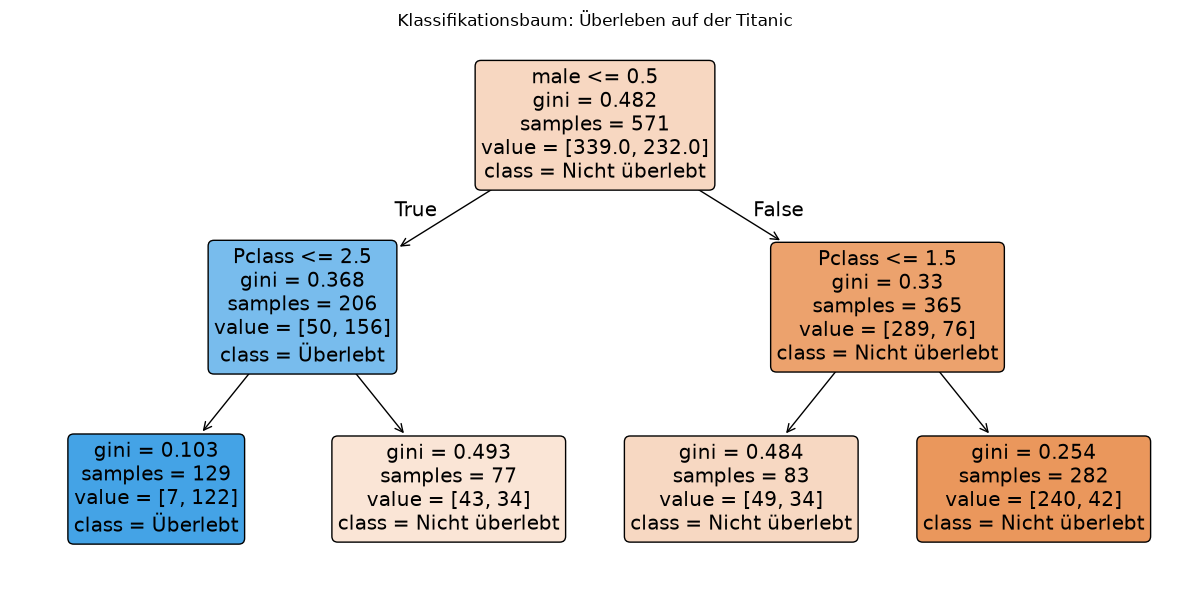

,Age,Fare,Pclass,male,predicted_class,probability_survived
0,30,10,3,1,0,0.149
1,30,80,1,0,1,0.946


In [10]:
#Verwenden, um einen Klassifikationsbaum zu trainieren, seine Regeln zu zeichnen und neue Klassen samt Wahrscheinlichkeiten vorherzusagen
from sklearn.tree import DecisionTreeClassifier, plot_tree
#VORAUSSETZUNG: pd und plt sind importiert, die Titanic-Trainingsdaten sind vorbereitet


#1. Baum erstellen und trainieren
classification_tree_titanic = DecisionTreeClassifier(
    max_depth=2,                                                                #Höchstens zwei Aufteilungen pro Pfad
    random_state=42
)
classification_tree_titanic.fit(X_train_titanic, y_train_titanic)
#ANPASSEN: max_depth und random_state gemäss Aufgabe setzen
#ANPASSEN: X_train_titanic und y_train_titanic durch deine Trainingsvariablen ersetzen


#2. Klassenreihenfolge prüfen und Baum zeichnen
print('Klassenreihenfolge:', classification_tree_titanic.classes_)
tree_class_names = ['Nicht überlebt', 'Überlebt']                               #Beschriftungen passend zu classes_ = [0, 1]
#ANPASSEN: Klassennamen in genau der angezeigten Klassenreihenfolge ersetzen

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(
    classification_tree_titanic,
    feature_names=list(X_train_titanic.columns),                                #Merkmalsnamen wie beim Training
    class_names=tree_class_names,
    filled=True, rounded=True, precision=3, ax=ax
)
ax.set_title('Klassifikationsbaum: Überleben auf der Titanic')
plt.tight_layout()
plt.show()
#ANPASSEN: X_train_titanic wie in Schritt 1 ersetzen und Titel an die Aufgabe anpassen
#ANPASSEN: Bei grösseren Bäumen figsize erhöhen, damit die Regeln lesbar bleiben


#3. Optional: Neue Beobachtungen erfassen
new_passengers_tree = pd.DataFrame({
    'Age': [30, 30],                                                            #Alter der beiden Personen
    'Fare': [10, 80],                                                           #Fahrpreis
    'Pclass': [3, 1],                                                           #Passagierklasse
    'male': [1, 0]                                                              #Erste Person männlich, zweite weiblich
})
new_passengers_tree = new_passengers_tree[X_train_titanic.columns]
#ANPASSEN: Alle Eingabespalten und Werte der neuen Beobachtungen einsetzen, jede Zeile beschreibt eine Beobachtung
#ANPASSEN: X_train_titanic wie in Schritt 1 ersetzen, damit die Spaltenreihenfolge stimmt


#4. Klassen und Wahrscheinlichkeiten vorhersagen
new_passenger_classes = classification_tree_titanic.predict(
    new_passengers_tree
)                                                                               #Klasse mit der höchsten Wahrscheinlichkeit auswählen

new_passenger_probabilities = classification_tree_titanic.predict_proba(
    new_passengers_tree
)[:, 1]                                                                         #Bei classes_ = [0, 1] die Wahrscheinlichkeit für Klasse 1 auswählen

display(
    new_passengers_tree.assign(
        predicted_class=new_passenger_classes,
        probability_survived=new_passenger_probabilities
    ).round(3)
)
#ANPASSEN: probability_survived passend zur betrachteten Zielklasse benennen
#ACHTUNG: [:, 1] gehört zur zweiten Klasse in classes_, deren Bedeutung prüfen
#HINWEIS: Schritte 3–4 weglassen, wenn keine neuen Einzelbeobachtungen verlangt sind
#HINWEIS: Für Testvorhersagen in predict() bzw. predict_proba() stattdessen X_test_titanic einsetzen

### Klassifikationsbaum beschneiden
- Weniger Regeln durch Pruning
- **Definition:** Pruning entfernt Zweige, deren Nutzen für die Trainingsanpassung im Verhältnis zur zusätzlichen Komplexität zu klein ist
- **Zweck und Anwendung:** Einen einfacheren Klassifikationsbaum erhalten und die Anpassung an zufällige Trainingsdetails begrenzen
- **Input:** Vorbereitete Trainingsmerkmale und Zielklassen, hier `X_train_titanic` und `y_train_titanic`
- **`ccp_alpha=0.0`:** Keine zusätzliche Pruning-Strafe, der Baum wächst bis zu den übrigen Stoppregeln
- **Grösseres `ccp_alpha`:** Bestraft zusätzliche Blätter stärker, dadurch kann der Baum kleiner werden
- **Grundidee:** Gewichtete Knotenunreinheit der Blätter plus Strafe für deren Anzahl minimieren, nicht direkt die Trainings-Accuracy optimieren
- **`.get_n_leaves()`:** Zeigt die Anzahl verbleibender Blätter
- **`.score(X_train, y_train)`:** Liefert beim Klassifikationsbaum die Accuracy auf den übergebenen Trainingsdaten, nicht R² oder AUC
- **Interpretation gemäss Musterlösung:** `alpha=0` ergibt 136 Blätter und ungefähr 98.8 % Trainings-Accuracy, `alpha=0.01` ergibt 5 Blätter und ungefähr 80.0 % → deutlich weniger Regeln bei schlechterer Trainingsanpassung
- **Interpretationsgrenze:** Die höhere Trainings-Accuracy genügt nicht zur Modellauswahl, ob der grössere Baum bei unbekannten Personen besser ist, zeigt dieser Vergleich nicht
- **Stolpersteine:** Ein zu stark beschnittener Baum kann underfitten, alpha anhand von Validierung bzw. CV auswählen, Werte nicht ungeprüft aus der Regression übernehmen

In [11]:
#Verwenden, um bei Klassifikationsbäumen die Auswirkungen von Pruning auf Blattanzahl und Trainings-Accuracy zu vergleichen
#VORAUSSETZUNG: pd und DecisionTreeClassifier sind importiert, Titanic-Trainingsdaten sind vorbereitet


#1. Pruning-Einstellungen festlegen
classification_pruning_alphas = [0.0, 0.01]                                     #Unbeschnittenen und beschnittenen Baum vergleichen
#ANPASSEN: Liste durch die vorgegebenen ccp_alpha-Werte ersetzen


#2. Für jede Einstellung einen neuen Baum trainieren
classification_pruning_rows = []

for current_alpha in classification_pruning_alphas:
    current_pruned_classifier = DecisionTreeClassifier(
        ccp_alpha=current_alpha,                                                #Aktuellen Pruning-Wert verwenden
        random_state=42
    )
    #ANPASSEN: random_state gemäss Aufgabe setzen, weitere Parameter nur ergänzen, wenn verlangt

    current_pruned_classifier.fit(X_train_titanic, y_train_titanic)
    current_training_accuracy = current_pruned_classifier.score(
        X_train_titanic, y_train_titanic
    )                                                                           #Anteil richtig klassifizierter Trainingspersonen
    #ANPASSEN: X_train_titanic und y_train_titanic bei fit() und score() durch deine Trainingsvariablen ersetzen

    classification_pruning_rows.append({
        'ccp_alpha': current_alpha,
        'Blätter': current_pruned_classifier.get_n_leaves(),
        'Trainings-Accuracy': current_training_accuracy
    })


#3. Ergebnisse anzeigen
display(pd.DataFrame(classification_pruning_rows).round(3))
#HINWEIS: Accuracy 0.8 entspricht 80 % richtig klassifizierten Trainingsbeobachtungen
#ACHTUNG: Die Tabelle bewertet keine Testleistung, alpha nicht allein nach Trainings-Accuracy auswählen
#HINWEIS: classification_tree_titanic aus dem vorherigen Eintrag bleibt unverändert

,ccp_alpha,Blätter,Trainings-Accuracy
0,0.00,136,0.988
1,0.01,5,0.800


## Weitere Klassifikationsmodelle

### Random Forest Classification
- Klassenwahrscheinlichkeiten vieler Bäume kombinieren
- **Definition:** Ein Random Forest trainiert viele Klassifikationsbäume auf Bootstrap-Stichproben und berücksichtigt pro Split eine zufällige Auswahl der Eingabemerkmale
- **Zweck und Anwendung:** Klassen vorhersagen und die Schwankungen einzelner Bäume durch Kombination reduzieren, hier Überleben auf der Titanic
- **Input und Voraussetzungen:** Numerische Trainingsmerkmale und bekannte Zielklassen, hier `X_train_titanic` und `y_train_titanic`
- **`n_estimators=100`:** Trainiert 100 Bäume
- **`max_features='sqrt'`:** Berücksichtigt pro Split ungefähr die Quadratwurzel der Anzahl Eingabemerkmale, bei vier Merkmalen sind es zwei, dies ist die Standardeinstellung des Klassifikationswalds
- **`max_depth`:** Begrenzt bei Bedarf die Tiefe jedes einzelnen Baums, ohne Angabe gilt keine feste Tiefengrenze
- **`.predict_proba(...)`:** Mittelt die Klassenwahrscheinlichkeiten der einzelnen Bäume
- **`.predict(...)`:** Wählt die Klasse mit der höchsten gemittelten Wahrscheinlichkeit, das ist nicht zwingend dieselbe Entscheidung wie eine Mehrheitsabstimmung über die Klassen der Einzelbäume
- **Bsp. aus den Folien:** Drei Bäume liefern für Klasse 1 die Wahrscheinlichkeiten 0.8, 0.6 und 0.3 → Mittelwert ≈ 0.567 → Klasse 1
- **Interpretation:** Eine ausgegebene Überlebenswahrscheinlichkeit beschreibt die Schätzung des gesamten Walds, nicht die Sicherheit einer einzelnen Entscheidung
- **Stolperstein:** Viele Bäume garantieren keine gute Vorhersagequalität, die Leistung anhand von CV und anschliessend Testdaten beurteilen
- **Abgrenzung:** Wie beim einzelnen Klassifikationsbaum richtet sich die Spaltenreihenfolge von `.predict_proba()` nach `.classes_`

In [12]:
#Verwenden, um Klassen und Wahrscheinlichkeiten mit einem Random Forest aus vielen Klassifikationsbäumen vorherzusagen
from sklearn.ensemble import RandomForestClassifier
#VORAUSSETZUNG: pd ist importiert, die Titanic-Trainings- und Testdaten sind vorbereitet


#1. Random Forest erstellen
forest_classifier_titanic = RandomForestClassifier(
    n_estimators=100,                                                           #100 Klassifikationsbäume erstellen
    max_features='sqrt',                                                        #Bei vier Eingaben zwei zufällige Merkmale pro Split prüfen
    random_state=42
)
#ANPASSEN: n_estimators, max_features und random_state gemäss Aufgabe ersetzen
#ANPASSEN: Falls verlangt, eine Tiefengrenze wie max_depth=5 ergänzen


#2. Modell trainieren
forest_classifier_titanic.fit(X_train_titanic, y_train_titanic)
#ANPASSEN: Beide Variablen durch deine vorbereiteten Trainingsmerkmale und Trainingsklassen ersetzen


#3. Testklassen und Wahrscheinlichkeiten vorhersagen
forest_test_classes_titanic = forest_classifier_titanic.predict(
    X_test_titanic
)
forest_test_probability_titanic = forest_classifier_titanic.predict_proba(
    X_test_titanic
)[:, 1]                                                                         #Bei Klassenreihenfolge [0, 1] die Wahrscheinlichkeit für Klasse 1 auswählen
#ANPASSEN: X_test_titanic an beiden Stellen durch deine Testmerkmale ersetzen

print('Klassenreihenfolge:', forest_classifier_titanic.classes_)
#ACHTUNG: [:, 1] gehört zur zweiten Klasse dieser Reihenfolge, deren fachliche Bedeutung prüfen


#4. Eingaben, tatsächliche Klassen und Vorhersagen kontrollieren
forest_check_titanic = X_test_titanic.copy()
forest_check_titanic['actual_survived'] = y_test_titanic
forest_check_titanic['predicted_class'] = forest_test_classes_titanic
forest_check_titanic['probability_survived'] = forest_test_probability_titanic

display(forest_check_titanic.head(10).round(3))
#ANPASSEN: X_test_titanic und y_test_titanic durch deine zusammengehörenden Testvariablen ersetzen
#ANPASSEN: actual_survived und probability_survived passend zur Zielklasse benennen
#HINWEIS: head(10) begrenzt nur die Anzeige, die Vorhersagen wurden für alle Testbeobachtungen berechnet


#5. Optional: Testmodell mit den bereits bekannten Kennzahlen bewerten
print(f'Test-Accuracy: {accuracy_score(y_test_titanic, forest_test_classes_titanic):.3f}')
print(f'Test-AUC: {roc_auc_score(y_test_titanic, forest_test_probability_titanic):.3f}')
display(pd.DataFrame(
    confusion_matrix(y_test_titanic, forest_test_classes_titanic, labels=[0, 1]),
    index=['Tatsächlich 0', 'Tatsächlich 1'],
    columns=['Vorhergesagt 0', 'Vorhergesagt 1']
))
#ANPASSEN: y_test_titanic an allen drei Stellen durch deine Testzielwerte ersetzen
#VORAUSSETZUNG: accuracy_score, roc_auc_score und confusion_matrix sind aus den vorherigen Einträgen importiert
#HINWEIS: Schritt 5 weglassen, wenn das Modell erst später nach der Auswahl abschliessend getestet werden soll

Klassenreihenfolge: [0 1]


,Age,Fare,Pclass,male,actual_survived,predicted_class,probability_survived
315,26.0,7.854,3,0,1,0,0.270
483,63.0,9.588,3,0,1,0,0.020
736,48.0,34.375,3,0,0,0,0.170
722,34.0,13.000,2,1,0,1,0.510
400,39.0,7.925,3,1,1,0,0.145
162,26.0,7.775,3,1,0,0,0.410
231,29.0,7.775,3,1,0,0,0.386
104,37.0,7.925,3,1,0,0,0.116
812,35.0,10.500,2,1,0,0,0.153
52,49.0,76.729,1,0,1,1,1.000


Test-Accuracy: 0.797
Test-AUC: 0.828


,Vorhergesagt 0,Vorhergesagt 1
Tatsächlich 0,72,13
Tatsächlich 1,16,42


### Gradient Boosting Classification
- Klassenwahrscheinlichkeiten schrittweise verbessern
- **Definition:** Kombiniert viele kleine Bäume, die nacheinander aufgebaut werden, jeder neue Baum soll das bisherige Modell verbessern
- **Zweck und Anwendung:** Klassen anhand mehrerer Merkmale vorhersagen, dabei auch nichtlineare Zusammenhänge erfassen, hier Überleben auf der Titanic
- **Input und Voraussetzungen:** Numerische Trainingsmerkmale und bekannte Zielklassen, hier `X_train_titanic` und `y_train_titanic`
- **Unterschied zur Regression:** Bei Klassifikation wird standardmässig Log-Loss verwendet, die neuen Bäume lernen passende negative Gradienten (Pseudo-Residuen), nicht einfach die falsch vorhergesagten 0/1-Klassen
- **Unterschied zum Random Forest:** Boosting baut Bäume nacheinander als Korrekturen auf, der Wald trainiert Bäume separat und mittelt ihre Klassenwahrscheinlichkeiten
- **`n_estimators=100`:** Führt bei dieser binären Klassifikation 100 Boosting-Schritte durch
- **`max_depth=2`:** Begrenzt jeden einzelnen Baum auf höchstens zwei Aufteilungen pro Pfad
- **`learning_rate=0.1`:** Skaliert den Beitrag jedes neuen Baums auf 10 %, kleinere Lernraten benötigen häufig mehr Schritte
- **`.predict_proba(...)`:** Liefert die Klassenwahrscheinlichkeiten des gesamten Ensembles, deren Reihenfolge steht in `.classes_`
- **`.predict(...)`:** Liefert die Klasse mit der höchsten geschätzten Wahrscheinlichkeit
- **Interpretation:** Eine Wahrscheinlichkeit für Klasse 1 beschreibt die Modellschätzung für diese Beobachtung, sie ist keine Trefferquote des gesamten Modells
- **Stolpersteine:** Baumtiefe, Lernrate und Anzahl Schritte wirken zusammen, mehr Schritte oder kleinere Lernraten garantieren keine bessere Leistung, Einstellungen anhand von CV vergleichen

In [13]:
#Verwenden, um Klassenwahrscheinlichkeiten mit nacheinander trainierten kleinen Bäumen zu verbessern
from sklearn.ensemble import GradientBoostingClassifier
#VORAUSSETZUNG: pd ist importiert, die Titanic-Trainingsdaten sind vorbereitet


#1. Boosting-Modell erstellen
boosting_classifier_titanic = GradientBoostingClassifier(
    n_estimators=100,                                                           #100 Boosting-Schritte durchführen
    max_depth=2,                                                                #Jeden einzelnen Baum auf Tiefe 2 begrenzen
    learning_rate=0.1,                                                          #Jeweils 10 % des neuen Baumbeitrags übernehmen
    random_state=42
)
#ANPASSEN: n_estimators, max_depth, learning_rate und random_state gemäss Aufgabe ersetzen


#2. Modell trainieren
boosting_classifier_titanic.fit(X_train_titanic, y_train_titanic)
#ANPASSEN: Beide Variablen durch deine Trainingsmerkmale und Trainingsklassen ersetzen


#3. Optional: Klassen und Wahrscheinlichkeiten für neue Beobachtungen berechnen
boosting_input_titanic = X_test_titanic                                         #Hier die zurückgehaltenen Testpersonen vorhersagen
#ANPASSEN: X_test_titanic durch deine Testmerkmale oder eine Tabelle mit neuen Beobachtungen ersetzen
#VORAUSSETZUNG: Dieselben Eingabespalten in derselben Reihenfolge wie beim Training

boosting_classes_titanic = boosting_classifier_titanic.predict(
    boosting_input_titanic
)
boosting_probability_titanic = boosting_classifier_titanic.predict_proba(
    boosting_input_titanic
)[:, 1]                                                                         #Bei classes_ = [0, 1] die Wahrscheinlichkeit für Klasse 1

print('Klassenreihenfolge:', boosting_classifier_titanic.classes_)
#ACHTUNG: Prüfen, ob die zweite Klasse tatsächlich die gewünschte positive Klasse ist


#4. Vorhersagen neben den Eingaben anzeigen
display(
    boosting_input_titanic.assign(
        predicted_class=boosting_classes_titanic,
        probability_survived=boosting_probability_titanic
    ).head(10).round(3)
)
#ANPASSEN: probability_survived passend zur Zielklasse benennen, head(10) für die gewünschte Zeilenzahl ändern
#HINWEIS: Schritte 3–4 weglassen, wenn zunächst nur das Training bzw. der anschliessende CV-Vergleich verlangt ist

Klassenreihenfolge: [0 1]


,Age,Fare,Pclass,male,predicted_class,probability_survived
315,26.0,7.854,3,0,0,0.435
483,63.0,9.588,3,0,0,0.132
736,48.0,34.375,3,0,0,0.410
722,34.0,13.000,2,1,0,0.237
400,39.0,7.925,3,1,0,0.088
162,26.0,7.775,3,1,0,0.134
231,29.0,7.775,3,1,0,0.122
104,37.0,7.925,3,1,0,0.063
812,35.0,10.500,2,1,0,0.237
52,49.0,76.729,1,0,1,0.971


### k-Nearest Neighbours, k-NN
- k-NN ordnet eine neue Beobachtung anhand der k nächstgelegenen Trainingsbeobachtungen einer Klasse zu
- Ablauf, k festlegen, Abstände berechnen, die k nächsten Nachbarn auswählen und deren häufigste Klasse vorhersagen
- Bei gleich gewichteten Nachbarn entspricht die Klassenwahrscheinlichkeit dem Anteil dieser Klasse unter den k Nachbarn
- Bsp. 3 von 5 Nachbarn gehören zu Klasse 1, Wahrscheinlichkeit für Klasse 1 ist `3 / 5 = 0.6`
- Euklidischer Abstand bei zwei Merkmalen, `√((x₁ − z₁)² + (x₂ − z₂)²)`
- Unterschiedlich skalierte Merkmale vorher skalieren, sonst können grosse Zahlenbereiche die Abstände dominieren
- Kleines k ergibt häufig eine empfindlichere Grenze mit höherer Varianz, grosses k glättet stärker und kann wichtige Muster übersehen
- k anhand von Validierung bzw. CV wählen, eine nötige Skalierung innerhalb der jeweiligen Trainingsdaten lernen

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = make_pipeline(
    StandardScaler(),                                 #Merkmale auf vergleichbare Grössenordnungen bringen
    KNeighborsClassifier(n_neighbors=5)                #Fünf nächste Nachbarn verwenden
)

knn_model.fit(X_train_titanic, y_train_titanic)        #Skalierung und Nachbarschaftsmodell nur am Training anpassen
knn_test_prediction = knn_model.predict(X_test_titanic)  #Testdaten automatisch gleich skalieren und Klassen vorhersagen

print('Test-Accuracy', round(
    accuracy_score(y_test_titanic, knn_test_prediction), 3
))

#ANPASSEN Die drei Datenvariablen durch deine Trainingsmerkmale, Trainingsklassen und Testmerkmale ersetzen
#ANPASSEN y_test_titanic durch die zugehörigen tatsächlichen Testklassen ersetzen
#ANPASSEN n_neighbors gemäss Aufgabe setzen oder anhand von CV auswählen

Test-Accuracy 0.776


### Stützvektormaschine (SVM)
- Klassen mit möglichst grossem Abstand trennen
- **Definition:** Eine Support Vector Machine sucht eine Entscheidungsgrenze, welche Klassen mit möglichst grossem Trennabstand (Margin) voneinander abgrenzt
- **Zweck und Anwendung:** Klassifikation anhand numerischer Merkmale, bei zwei Eingaben lässt sich eine lineare Entscheidungsgrenze als Gerade darstellen, bei mehr Eingaben als Hyperebene
- **Input und Voraussetzungen:** Numerische Features und bekannte Klassen, unterschiedlich skalierte Merkmale können das Ergebnis stark beeinflussen, eine nötige Skalierung nur auf den Trainingsdaten lernen und in CV innerhalb einer Pipeline durchführen
- **Margin – Trennabstand:** Abstand zwischen der Entscheidungsgrenze und den begrenzenden Rändern, ein grosser Abstand soll die Trennung stabiler machen
- **Support Vectors – Stützvektoren:** Entscheidende Trainingsbeobachtungen am Rand oder innerhalb der Margin, bei einer weichen Trennung können auch falsch klassifizierte Beobachtungen dazugehören
- **Soft Margin – Weiche Trennung:** Erlaubt Verletzungen des Trennabstands und ggf. Fehlklassifikationen, damit einzelne problematische Trainingspunkte die Grenze nicht zu stark bestimmen
- **Parameter `C`:** Steuert die Bestrafung von Margin-Verletzungen, nicht die Breite der Margin direkt
- **Kleines `C`:** Stärkere Regularisierung, Verletzungen werden weniger stark bestraft, tendenziell breitere Margin und mehr zugelassene Trainingsfehler
- **Grosses `C`:** Verletzungen werden stärker bestraft, tendenziell engere Anpassung an die Trainingsdaten mit möglichem Overfitting
- **Stolperstein:** Ein grosses C garantiert weder fehlerfreie Trennung noch bessere Testleistung, die passende Einstellung anhand von Validierung bzw. CV wählen
- **Kernel – Kernelfunktion:** Berechnet Ähnlichkeiten so, als würden die Daten in einem anderen Merkmalsraum betrachtet, dadurch sind auch nichtlineare Entscheidungsgrenzen möglich
- **Linearer Kernel:** Ermöglicht eine gerade bzw. ebene Entscheidungsgrenze
- **Nichtlinearer Kernel:** Ermöglicht gekrümmte Grenzen, bspw. mit einem RBF-Kernel
- **Output und Interpretation:** Das Modell liefert vorhergesagte Klassen und je nach Umsetzung Entscheidungsscores, diese Scores beschreiben die Lage relativ zur Grenze und sind keine Wahrscheinlichkeiten
- **Bewertung:** Klassen mit Confusion Matrix und passenden Kennzahlen bewerten, geeignete Entscheidungsscores können für ROC/AUC verwendet werden
- **Grafik lesen:** Entscheidungsgrenze, Margin und Stützvektoren unterscheiden, breite Margin und wenige Trainingsfehler müssen gegeneinander abgewogen werden

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score

svm_model = make_pipeline(
    StandardScaler(),                                 #Skalierung nur aus den Trainingsdaten lernen
    SVC(kernel='rbf', C=1.0)                           #SVM mit nichtlinearer Entscheidungsgrenze erstellen
)

svm_model.fit(X_train_titanic, y_train_titanic)        #SVM auf den skalierten Trainingsdaten trainieren
svm_test_prediction = svm_model.predict(X_test_titanic)  #Klassen der Testbeobachtungen vorhersagen
svm_test_score = svm_model.decision_function(X_test_titanic)  #Kontinuierliche Entscheidungsscores für ROC und AUC berechnen

print('Klassenreihenfolge', svm_model.classes_)
print('Test-Accuracy', round(
    accuracy_score(y_test_titanic, svm_test_prediction), 3
))
print('Test-AUC', round(
    roc_auc_score(y_test_titanic, svm_test_score), 3
))

#ANPASSEN Trainingsvariablen und Testvariablen gemäss Aufgabe ersetzen
#ANPASSEN kernel und C gemäss Aufgabe setzen
#ACHTUNG Dieses AUC-Beispiel setzt zwei Klassen voraus, höhere Scores gehören zur zweiten Klasse in classes_
#ERKENNTNIS Entscheidungsscores sind keine Wahrscheinlichkeiten

Klassenreihenfolge [0 1]
Test-Accuracy 0.804
Test-AUC 0.868


## Modelle vergleichen & einstellen

### Klassifikationsmodelle mit CV-AUC vergleichen
- Die bessere Rangtrennung bestimmen
- **Definition:** Trainiert und bewertet jedes Modell mehrfach innerhalb der Trainingsdaten und vergleicht die durchschnittliche AUC der Validierungsdurchläufe
- **Zweck und Anwendung:** Klassifikationsmodelle vergleichen, wenn ihre Fähigkeit zur Rangtrennung der Klassen beurteilt werden soll
- **Input und Voraussetzungen:** Modelle, numerische Trainingsmerkmale und zugehörige binäre Zielklassen, beide Klassen müssen in jedem Validierungsfold vorkommen
- **`cross_val_score(..., cv=5, scoring='roc_auc')`:** Führt fünf Trainings-/Validierungsdurchläufe durch und liefert pro Fold eine AUC
- **Geschichtete Folds:** Bei binärer Klassifikation verwendet `cv=5` standardmässig StratifiedKFold ohne zusätzliches Mischen, die Klassenanteile bleiben ungefähr erhalten
- **Wahrscheinlichkeiten:** Die Bewertungsfunktion verwendet geeignete Wahrscheinlichkeiten bzw. Scores des Modells automatisch, vorhergesagte 0/1-Klassen müssen nicht selbst erstellt werden
- **Keine RMSE-Umrechnung:** AUC-Werte direkt mitteln, weder das Vorzeichen wechseln noch eine Wurzel ziehen
- **Output:** Mittlere CV-AUC je Modell, grössere Werte bedeuten bessere Rangtrennung, 0.5 entspricht der Zufallsreferenz und 1 perfekter Trennung
- **Interpretation gemäss Musterlösung:** Random Forest erreicht ungefähr 0.871 und Boosting 0.861, der Wald schneidet auf diesen Folds etwas besser ab
- **Interpretationsgrenze:** Der Unterschied von 0.010 ist klein und beweist keine allgemeine Überlegenheit, mit anderen Daten oder Einstellungen kann die Reihenfolge wechseln
- **Stolperstein:** AUC ist keine Accuracy und bewertet keine konkrete Entscheidungsgrenze, für praktische Entscheidungen bleiben Fehlerkosten und Schwellenwert relevant
- **Danach:** Ein ausgewähltes Modell auf allen Trainingsdaten trainieren und anschliessend auf den zurückgehaltenen Testdaten bewerten, `cross_val_score()` liefert kein fertig trainiertes Modell zurück

In [16]:
#Verwenden, um binäre Klassifikationsmodelle anhand ihrer mittleren Validierungs-AUC zu vergleichen
from sklearn.model_selection import cross_val_score
#VORAUSSETZUNG: pd, RandomForestClassifier und GradientBoostingClassifier sind importiert


#1. Trainingsdaten zuordnen
classification_cv_X = X_train_titanic
classification_cv_y = y_train_titanic
#ANPASSEN: Rechts deine Trainingsmerkmale und Trainingsklassen einsetzen, keine Testdaten verwenden


#2. Zu vergleichende Modelle festlegen
classification_cv_models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    'Boosting': GradientBoostingClassifier(
        n_estimators=100, max_depth=2,
        learning_rate=0.1, random_state=42
    )
}
#ANPASSEN: Modelle und Parameter gemäss Aufgabe ersetzen, links stehen frei wählbare Anzeigenamen


#3. Jedes Modell mit derselben CV prüfen
classification_cv_folds = 5
#ANPASSEN: Anzahl Folds gemäss Aufgabe ersetzen, jede Klasse benötigt hier mindestens so viele Trainingsfälle

classification_cv_rows = []

for model_name, candidate_model in classification_cv_models.items():
    candidate_auc_scores = cross_val_score(
        candidate_model,
        classification_cv_X, classification_cv_y,
        cv=classification_cv_folds,                                             #Bei Klassifikation automatisch geschichtete Folds
        scoring='roc_auc'                                                       #AUC anhand von Wahrscheinlichkeiten bzw. Scores bewerten
    )

    classification_cv_rows.append({
        'Modell': model_name,
        'Mittlere CV-AUC': candidate_auc_scores.mean()
    })                                                                          #AUC direkt mitteln, keine Wurzel und kein Vorzeichenwechsel

    print(f'{model_name} – AUC je Fold:', candidate_auc_scores.round(3))
#HINWEIS: Schritt 3 bleibt beim AUC-Vergleich nach Anpassung von Schritt 1–2 unverändert
#ANPASSEN: Bei einer anderen verlangten Kennzahl scoring und die Ergebnisbeschriftungen passend ändern


#4. Ergebnisse sortiert anzeigen
classification_cv_results = (
    pd.DataFrame(classification_cv_rows)
    .set_index('Modell')
    .sort_values('Mittlere CV-AUC', ascending=False)
)

display(classification_cv_results.round(3))                                     #Höchste mittlere AUC steht oben
#ACHTUNG: Falls du die Kennzahl änderst, auch die Sortierrichtung prüfen, bei AUC ist grösser besser
#HINWEIS: Dieser Block vergleicht Modelle, er führt noch keine abschliessende Testbewertung durch

Random Forest – AUC je Fold: [0.85  0.872 0.884 0.898 0.85 ]
Boosting – AUC je Fold: [0.856 0.898 0.873 0.891 0.786]


,Mittlere CV-AUC
Modell,
Random Forest,0.871
Boosting,0.861


### GridSearchCV
- Modelleinstellungen systematisch vergleichen
- **Definition:** Probiert alle Kombinationen vorgegebener Hyperparameter aus und bewertet jede Kombination mit Cross-Validation
- **Zweck und Anwendung:** Verwenden, wenn die beste Einstellung innerhalb einer vorgegebenen Auswahl gesucht ist, bspw. Merkmalsauswahl und Mindestgrösse der Blätter eines Random Forest
- **Input und Voraussetzungen:** Ein Modell, ein Parametergitter und vorbereitete Trainingsdaten, hier Auswahl anhand der mittleren CV-AUC
- **Hyperparameter:** Einstellungen, die vor dem Training festgelegt werden, bspw. `min_samples_leaf`, im Unterschied zu den beim Training gelernten Baumregeln
- **`param_grid`:** Gibt die zu prüfenden Werte je Parameter vor, alle möglichen Kombinationen werden getestet
- **`max_features=['sqrt', 1.0]`:** Bei vier Eingaben entweder zwei zufällige Merkmale oder alle vier Merkmale pro Split berücksichtigen
- **`min_samples_leaf=[1, 5, 20]`:** Ein Blatt muss mindestens 1, 5 oder 20 Trainingsbeobachtungen enthalten
- **Anzahl Kombinationen:** `2 × 3 = 6`, bei fünf Folds entstehen 30 CV-Trainingsläufe, anschliessend folgt standardmässig ein zusätzliches Training der besten Kombination auf allen Trainingsdaten
- **`.best_params_`:** Einstellungen mit der höchsten mittleren CV-AUC
- **`.best_score_`:** Mittlere CV-AUC der ausgewählten Kombination, keine Test-AUC
- **`.best_estimator_`:** Bestes Modell, standardmässig bereits auf allen übergebenen Trainingsdaten trainiert
- **`.predict_proba(X_test)`:** Verwendet automatisch dieses beste Modell für die Testwahrscheinlichkeiten
- **Interpretation:** Die Suche findet die beste Kombination innerhalb des vorgegebenen Gitters, nicht die allgemein besten denkbaren Einstellungen
- **Abschliessende Bewertung:** Test-AUC aus Wahrscheinlichkeiten berechnen, für eine Confusion Matrix diese Wahrscheinlichkeiten mit einem festgelegten Schwellenwert in Klassen umwandeln
- **Stolpersteine:** Nur Trainingsdaten an `.fit()` übergeben, weder Parameter noch Schwellenwert nachträglich anhand der Testergebnisse optimieren
- **Voraussetzungen:** Beide Klassen müssen in jedem Validierungsfold vorkommen, nötige gelernte Vorverarbeitung gehört in eine Pipeline innerhalb der Suche

In [17]:
#Verwenden, um vorgegebene Hyperparameter mit CV-AUC zu vergleichen und das ausgewählte Modell abschliessend zu testen
from sklearn.model_selection import GridSearchCV
#VORAUSSETZUNG: pd, RandomForestClassifier, roc_auc_score und confusion_matrix sind importiert


#1. Vorbereitete Trainings- und Testdaten zuordnen
search_X_train = X_train_titanic
search_y_train = y_train_titanic
search_X_test = X_test_titanic
search_y_test = y_test_titanic
#ANPASSEN: Rechts die vier zusammengehörenden Trainings- und Testvariablen deiner Aufgabe einsetzen


#2. Grundmodell und zu prüfende Einstellungen festlegen
search_base_model = RandomForestClassifier(
    n_estimators=100,                                                           #Für alle Kombinationen 100 Bäume verwenden
    random_state=42
)

search_parameters = {
    'max_features': ['sqrt', 1.0],                                              #Zwei Varianten der Merkmalsauswahl
    'min_samples_leaf': [1, 5, 20]                                              #Drei mögliche Mindestgrössen der Blätter
}
#ANPASSEN: Grundmodell und feste Parameter gemäss Aufgabe ersetzen
#ANPASSEN: Im Gitter Parameternamen und Wertelisten gemäss Aufgabe einsetzen
#ACHTUNG: Parameternamen müssen zum gewählten Modell passen, im Gitter geprüfte Werte überschreiben dessen feste Einstellungen


#3. Suche nur auf den Trainingsdaten durchführen
classification_grid = GridSearchCV(
    estimator=search_base_model,
    param_grid=search_parameters,
    cv=5,                                                                       #Jede Kombination mit fünf Folds prüfen
    scoring='roc_auc',                                                          #Höchste mittlere AUC gewinnt
    refit=True                                                                  #Beste Kombination danach auf allen Trainingsdaten trainieren
)
classification_grid.fit(search_X_train, search_y_train)
#ANPASSEN: cv und scoring gemäss Aufgabe setzen
#HINWEIS: Bei refit=True ist nach fit() kein zusätzliches Training des Gewinners nötig


#4. Ausgewählte Einstellungen anzeigen
print('Getestete Kombinationen:', len(classification_grid.cv_results_['params']))
print('Beste Einstellungen:', classification_grid.best_params_)
print(f'Beste CV-AUC: {classification_grid.best_score_:.3f}')
#ANPASSEN: Bei anderer Bewertungskennzahl die Beschriftung «CV-AUC» ersetzen


#5. Bestes Modell auf den Testdaten bewerten
search_test_probability = classification_grid.predict_proba(
    search_X_test
)[:, 1]                                                                         #Bei Klassenreihenfolge [0, 1] die Wahrscheinlichkeit für Klasse 1

print('Klassenreihenfolge:', classification_grid.classes_)
print(f'Test-AUC: {roc_auc_score(search_y_test, search_test_probability):.3f}')
#ACHTUNG: [:, 1] gehört zur zweiten Klasse in classes_, deren Bedeutung prüfen
#ANPASSEN: Falls keine Test-AUC verlangt ist, die entsprechende Ausgabe weglassen


#6. Confusion Matrix bei festgelegtem Schwellenwert anzeigen
search_threshold = 0.5
#ANPASSEN: Durch den vorgegebenen oder vorher anhand von Validierungsdaten festgelegten Schwellenwert ersetzen

search_test_classes = (
    search_test_probability >= search_threshold
).astype(int)                                                                   #Ab der Grenze Klasse 1, sonst Klasse 0

display(pd.DataFrame(
    confusion_matrix(search_y_test, search_test_classes, labels=[0, 1]),
    index=['Tatsächlich 0', 'Tatsächlich 1'],
    columns=['Vorhergesagt 0', 'Vorhergesagt 1']
))
#HINWEIS: Schritte 5–6 weglassen, wenn nur die Parametersuche mit CV verlangt ist
#ACHTUNG: Nach Sichtung der Testergebnisse keine neue Parameter- oder Schwellenwertsuche starten

Getestete Kombinationen: 6
Beste Einstellungen: {'max_features': 'sqrt', 'min_samples_leaf': 1}
Beste CV-AUC: 0.871
Klassenreihenfolge: [0 1]
Test-AUC: 0.828


,Vorhergesagt 0,Vorhergesagt 1
Tatsächlich 0,71,14
Tatsächlich 1,15,43
